# Eksplorasi dan Implementasi Python untuk Probabilitas dan Distribusi Probabilitas

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/raihanahmada/Probabilitas-dan-Distribusi/blob/main/Probabilitas_dan_Distribusi.ipynb)

**Mata kuliah:** Probabilitas dan Statistika - Teknik Informatika, Politeknik Caltex Riau  
**Dosen:** Mona Elviyenti, S.Si., M.Si.  
**Nama:** Kurnia Setiawan  
**NIM:** 2455301224

Notebook ini berisi:
- **A. Daftar Library** - 19 library Python beserta fungsi, kegunaan, dan contoh kode
- **B. Probabilitas** - 17 soal (P1-P17)
- **C. Distribusi Probabilitas** - 17 soal (D1-D17), distribusi diskrit dan kontinu
- **D. Kesimpulan Umum**

Format tiap soal: **1. Soal -> 2. Penyelesaian manual -> 3. Kode Python -> 4. Output -> 5. Perbandingan manual vs Python -> 6. Interpretasi -> 7. Kesimpulan**.
Semua simulasi memakai `np.random.seed(42)` / `random.seed(42)` sehingga hasilnya reproducible. Jalankan dengan **Runtime -> Run all**.

## Persiapan: instalasi & import
Semua library sudah terpasang di Google Colab, sel pip di bawah hanya untuk berjaga-jaga. Semua import dan fungsi bantu (`tabel_banding`, `ringkas_simulasi`, `plot_distribusi`) ada di sel kedua.

In [1]:
!pip install -q --root-user-action=ignore numpy scipy sympy pandas matplotlib seaborn statsmodels scikit-learn

In [2]:
import math, itertools, random, fractions, statistics, collections, hashlib
from fractions import Fraction
from collections import Counter

import numpy as np
import pandas as pd
import scipy.stats as stats
import sympy as sp
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from statsmodels.stats.proportion import proportion_confint
from statsmodels.distributions.empirical_distribution import ECDF
import scipy.special as sps
import scipy.integrate as integrate
import secrets
from decimal import Decimal, getcontext
from sklearn.naive_bayes import MultinomialNB
from sklearn.feature_extraction.text import CountVectorizer

np.random.seed(42)
random.seed(42)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.precision", 6)

def tabel_banding(baris):
    df = pd.DataFrame(baris, columns=["Besaran", "Manual", "Python"])
    df["Selisih"] = (df["Manual"] - df["Python"]).abs()
    print(df.to_string(index=False, float_format=lambda v: f"{v:.6f}"))

def ringkas_simulasi(sampel, dist):
    print(f"Mean    teori = {dist.mean():.6f} | simulasi = {np.mean(sampel):.6f}")
    print(f"Varians teori = {dist.var():.6f} | simulasi = {np.var(sampel):.6f}")

def plot_distribusi(dist, sampel, x, judul, diskrit=True):
    fig, ax = plt.subplots(1, 3, figsize=(15, 4))
    if diskrit:
        ax[0].bar(x, dist.pmf(x), color="steelblue"); ax[0].set_title("PMF teori")
        ax[1].step(x, dist.cdf(x), where="post", color="darkorange"); ax[1].set_title("CDF teori")
        nilai, frek = np.unique(sampel, return_counts=True)
        m = (nilai >= x.min()) & (nilai <= x.max())
        ax[2].bar(nilai[m], frek[m] / len(sampel), alpha=0.5, label="Simulasi")
        ax[2].plot(x, dist.pmf(x), "ro-", ms=4, label="Teori (PMF)")
    else:
        ax[0].plot(x, dist.pdf(x), color="steelblue"); ax[0].fill_between(x, dist.pdf(x), alpha=0.3)
        ax[0].set_title("PDF teori")
        ax[1].plot(x, dist.cdf(x), color="darkorange"); ax[1].set_title("CDF teori")
        ax[2].hist(sampel[(sampel >= x.min()) & (sampel <= x.max())], bins=60, density=True,
                   alpha=0.5, label="Simulasi")
        ax[2].plot(x, dist.pdf(x), "r-", lw=2, label="Teori (PDF)")
    ax[2].set_title("Histogram simulasi vs teori"); ax[2].legend()
    fig.suptitle(judul, fontsize=13, fontweight="bold")
    plt.tight_layout(); plt.show()

print("Semua library berhasil di-import. NumPy", np.__version__, "| SciPy", __import__("scipy").__version__)

Semua library berhasil di-import. NumPy 2.5.3 | SciPy 1.18.1


# A. Daftar Library Python

| No | Library | Fungsi utama | Kegunaan |
|---|---|---|---|
| 1 | `math` | factorial, perm, comb, exp, log, sqrt | Library bawaan Python untuk operasi matematika dasar. Dipakai buat hitung faktorial, permutasi, kombinasi, dan fungsi eksponensial yang muncul di rumus Binomial, Poisson, dll. |
| 2 | `itertools` | product, permutations, combinations | Membangkitkan seluruh ruang sampel secara eksplisit (enumerasi). Cocok buat verifikasi jawaban manual dengan cara menghitung satu per satu. |
| 3 | `random` | seed, randint, choice, choices, sample | Pembangkit bilangan acak bawaan Python. Enak dipakai untuk simulasi kecil yang logikanya per kejadian, misalnya Monty Hall atau pengambilan sampel tanpa pengembalian. |
| 4 | `fractions` | Fraction | Menyimpan peluang sebagai pecahan eksak (misal 1/15), jadi hasil Python bisa dicocokkan persis dengan hitungan manual tanpa galat desimal. |
| 5 | `statistics` | mean, median, pvariance, stdev | Statistik deskriptif bawaan Python. Dipakai untuk menghitung rata-rata dan varians hasil simulasi kecil. |
| 6 | `collections` | Counter | Menghitung frekuensi kemunculan tiap kejadian (misalnya status code log). Frekuensi relatif = pendekatan peluang empiris. |
| 7 | `numpy` | random.seed, random.rand/randint/normal/binomial/poisson/..., mean, var, cumsum | Library komputasi numerik berbasis array. Paling cepat untuk simulasi Monte Carlo dengan ratusan ribu sampai jutaan percobaan sekaligus (vektorisasi). |
| 8 | `scipy.stats` | binom, poisson, geom, nbinom, hypergeom, randint, uniform, norm, expon, gamma, beta, chi2_contingency | Kumpulan objek distribusi probabilitas lengkap: pmf/pdf, cdf, sf, ppf, mean, var, interval, rvs. Ini library utama untuk bagian distribusi. |
| 9 | `sympy` | symbols, integrate, binomial, subs, lambdify | Matematika simbolik. Bisa menurunkan rumus secara eksak (misalnya integral PDF atau rumus Bayes) lalu disubstitusi angka. |
| 10 | `pandas` | DataFrame, crosstab, value_counts | Mengolah data tabel. crosstab sangat praktis untuk tabel kontingensi, peluang gabungan, marginal, dan bersyarat. |
| 11 | `matplotlib` | pyplot.bar, plot, step, hist, subplots | Library visualisasi dasar untuk menggambar PMF, PDF, CDF, histogram, dan grafik konvergensi. |
| 12 | `seaborn` | histplot, heatmap, set_theme | Visualisasi statistik di atas matplotlib, tampilannya lebih rapi. Dipakai untuk heatmap tabel kontingensi dan histogram + KDE. |
| 13 | `statsmodels` | stats.proportion.proportion_confint, distributions.ECDF | Library statistik/ekonometrika. Dipakai untuk interval kepercayaan proporsi (Wilson) dan fungsi distribusi empiris (ECDF). |
| 14 | `hashlib` | md5, sha256, hexdigest | Fungsi hash kriptografis. Dipakai pada soal birthday problem untuk mensimulasikan tabrakan hash secara nyata. |
| 15 | `scipy.special` | comb, factorial, gamma, beta | Fungsi matematika khusus. Dipakai untuk kombinasi bilangan besar secara eksak, serta fungsi Gamma dan Beta yang muncul di rumus distribusi kontinu. |
| 16 | `scipy.integrate` | quad, dblquad | Integral numerik. Peluang variabel kontinu = luas di bawah kurva PDF, jadi bisa dihitung langsung dengan integral (termasuk integral ganda untuk peluang geometris). |
| 17 | `secrets` | choice, token_hex, randbelow | Pembangkit bilangan acak yang aman secara kriptografis. Berbeda dengan random, secrets dipakai untuk membuat password atau token reset yang tidak bisa ditebak. |
| 18 | `decimal` | Decimal, getcontext().prec | Aritmetika desimal dengan presisi yang bisa diatur. Berguna untuk peluang yang sangat kecil (misalnya 1/62^8) supaya tidak hilang karena pembulatan float. |
| 19 | `scikit-learn` | naive_bayes.MultinomialNB, feature_extraction.text.CountVectorizer | Library machine learning. Classifier Naive Bayes di dalamnya adalah penerapan langsung teorema Bayes untuk klasifikasi teks seperti filter spam. |

### A.1 `math`
- **Fungsi utama:** `factorial, perm, comb, exp, log, sqrt`
- **Kegunaan:** Library bawaan Python untuk operasi matematika dasar. Dipakai buat hitung faktorial, permutasi, kombinasi, dan fungsi eksponensial yang muncul di rumus Binomial, Poisson, dll.

In [3]:
print("5!       =", math.factorial(5))
print("P(8,3)   =", math.perm(8, 3))
print("C(10,3)  =", math.comb(10, 3))
print("e^-2     =", math.exp(-2))

5!       = 120
P(8,3)   = 336
C(10,3)  = 120
e^-2     = 0.1353352832366127


### A.2 `itertools`
- **Fungsi utama:** `product, permutations, combinations`
- **Kegunaan:** Membangkitkan seluruh ruang sampel secara eksplisit (enumerasi). Cocok buat verifikasi jawaban manual dengan cara menghitung satu per satu.

In [4]:
dadu2 = list(itertools.product(range(1, 7), repeat=2))
print("Jumlah titik sampel 2 dadu:", len(dadu2))
print("Kombinasi 2 dari ABC:", list(itertools.combinations("ABC", 2)))
print("Permutasi 2 dari ABC:", len(list(itertools.permutations("ABC", 2))))

Jumlah titik sampel 2 dadu: 36
Kombinasi 2 dari ABC: [('A', 'B'), ('A', 'C'), ('B', 'C')]
Permutasi 2 dari ABC: 6


### A.3 `random`
- **Fungsi utama:** `seed, randint, choice, choices, sample`
- **Kegunaan:** Pembangkit bilangan acak bawaan Python. Enak dipakai untuk simulasi kecil yang logikanya per kejadian, misalnya Monty Hall atau pengambilan sampel tanpa pengembalian.

In [5]:
random.seed(42)
print("Lempar dadu 10x :", [random.randint(1, 6) for _ in range(10)])
print("Pilih 3 server  :", random.sample(["srv1", "srv2", "srv3", "srv4", "srv5"], 3))
print("Choices berbobot:", random.choices(["OK", "ERR"], weights=[9, 1], k=8))

Lempar dadu 10x : [6, 1, 1, 6, 3, 2, 2, 2, 6, 1]
Pilih 3 server  : ['srv5', 'srv1', 'srv3']
Choices berbobot: ['OK', 'OK', 'OK', 'OK', 'OK', 'OK', 'OK', 'OK']


### A.4 `fractions`
- **Fungsi utama:** `Fraction`
- **Kegunaan:** Menyimpan peluang sebagai pecahan eksak (misal 1/15), jadi hasil Python bisa dicocokkan persis dengan hitungan manual tanpa galat desimal.

In [6]:
p = Fraction(3, 10) * Fraction(2, 9)
print("3/10 x 2/9 =", p, "=", float(p))
print("1/6 + 1/3  =", Fraction(1, 6) + Fraction(1, 3))

3/10 x 2/9 = 1/15 = 0.06666666666666667
1/6 + 1/3  = 1/2


### A.5 `statistics`
- **Fungsi utama:** `mean, median, pvariance, stdev`
- **Kegunaan:** Statistik deskriptif bawaan Python. Dipakai untuk menghitung rata-rata dan varians hasil simulasi kecil.

In [7]:
latensi = [120, 135, 128, 140, 150, 132, 127]
print("mean  =", statistics.mean(latensi))
print("median=", statistics.median(latensi))
print("pvariance =", round(statistics.pvariance(latensi), 4), "| stdev =", round(statistics.stdev(latensi), 4))

mean  = 133.14285714285714
median= 132
pvariance = 81.8367 | stdev = 9.7712


### A.6 `collections`
- **Fungsi utama:** `Counter`
- **Kegunaan:** Menghitung frekuensi kemunculan tiap kejadian (misalnya status code log). Frekuensi relatif = pendekatan peluang empiris.

In [8]:
log = ["200", "200", "404", "200", "500", "404", "200"]
c = Counter(log)
print(c)
print("Frekuensi relatif 200:", c["200"] / len(log))

Counter({'200': 4, '404': 2, '500': 1})
Frekuensi relatif 200: 0.5714285714285714


### A.7 `numpy`
- **Fungsi utama:** `random.seed, random.rand/randint/normal/binomial/poisson/..., mean, var, cumsum`
- **Kegunaan:** Library komputasi numerik berbasis array. Paling cepat untuk simulasi Monte Carlo dengan ratusan ribu sampai jutaan percobaan sekaligus (vektorisasi).

In [9]:
np.random.seed(42)
lempar = np.random.randint(0, 2, size=100_000)
print("Proporsi kepala:", lempar.mean())
print("Sampel normal  :", np.random.normal(0, 1, 5).round(4))

Proporsi kepala: 0.50063
Sampel normal  : [-0.0191  1.2073  0.6253 -0.8047  1.7871]


### A.8 `scipy.stats`
- **Fungsi utama:** `binom, poisson, geom, nbinom, hypergeom, randint, uniform, norm, expon, gamma, beta, chi2_contingency`
- **Kegunaan:** Kumpulan objek distribusi probabilitas lengkap: pmf/pdf, cdf, sf, ppf, mean, var, interval, rvs. Ini library utama untuk bagian distribusi.

In [10]:
X = stats.binom(n=10, p=0.3)
print("P(X=3) =", round(X.pmf(3), 6), "| P(X<=3) =", round(X.cdf(3), 6))
print("E[X] =", X.mean(), "| Var(X) =", X.var())
print("P(Z<1.96) =", round(stats.norm.cdf(1.96), 6))

P(X=3) = 0.266828 | P(X<=3) = 0.649611
E[X] = 3.0 | Var(X) = 2.1
P(Z<1.96) = 0.975002


### A.9 `sympy`
- **Fungsi utama:** `symbols, integrate, binomial, subs, lambdify`
- **Kegunaan:** Matematika simbolik. Bisa menurunkan rumus secara eksak (misalnya integral PDF atau rumus Bayes) lalu disubstitusi angka.

In [11]:
x, lam = sp.symbols("x lambda", positive=True)
pdf = lam * sp.exp(-lam * x)
print("Integral PDF eksponensial 0..oo =", sp.integrate(pdf, (x, 0, sp.oo)))
print("E[X] =", sp.integrate(x * pdf, (x, 0, sp.oo)))
print("C(10,3) simbolik =", sp.binomial(10, 3))

Integral PDF eksponensial 0..oo = 1
E[X] = 1/lambda
C(10,3) simbolik = 120


### A.10 `pandas`
- **Fungsi utama:** `DataFrame, crosstab, value_counts`
- **Kegunaan:** Mengolah data tabel. crosstab sangat praktis untuk tabel kontingensi, peluang gabungan, marginal, dan bersyarat.

In [12]:
df = pd.DataFrame({"os": ["Android", "iOS", "Android", "Android", "iOS"],
                   "crash": ["Ya", "Tidak", "Tidak", "Ya", "Tidak"]})
print(pd.crosstab(df["os"], df["crash"], margins=True))
print(df["crash"].value_counts(normalize=True))

crash    Tidak  Ya  All
os                     
Android      1   2    3
iOS          2   0    2
All          3   2    5
crash
Tidak    0.6
Ya       0.4
Name: proportion, dtype: float64


### A.11 `matplotlib`
- **Fungsi utama:** `pyplot.bar, plot, step, hist, subplots`
- **Kegunaan:** Library visualisasi dasar untuk menggambar PMF, PDF, CDF, histogram, dan grafik konvergensi.

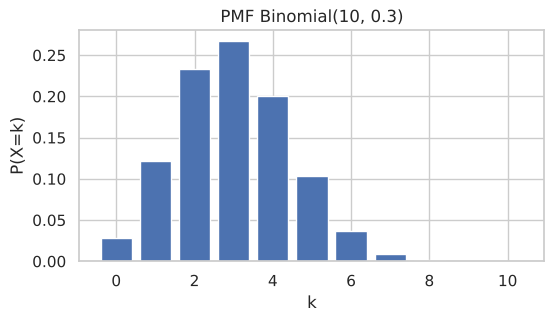

In [13]:
k = np.arange(0, 11)
plt.figure(figsize=(6, 3))
plt.bar(k, stats.binom.pmf(k, 10, 0.3)); plt.title("PMF Binomial(10, 0.3)")
plt.xlabel("k"); plt.ylabel("P(X=k)"); plt.show()

### A.12 `seaborn`
- **Fungsi utama:** `histplot, heatmap, set_theme`
- **Kegunaan:** Visualisasi statistik di atas matplotlib, tampilannya lebih rapi. Dipakai untuk heatmap tabel kontingensi dan histogram + KDE.

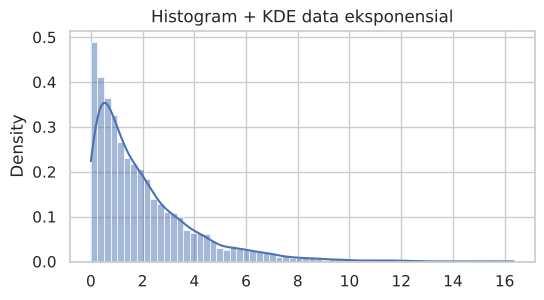

In [14]:
np.random.seed(42)
plt.figure(figsize=(6, 3))
sns.histplot(np.random.exponential(2, 5000), kde=True, stat="density")
plt.title("Histogram + KDE data eksponensial"); plt.show()

### A.13 `statsmodels`
- **Fungsi utama:** `stats.proportion.proportion_confint, distributions.ECDF`
- **Kegunaan:** Library statistik/ekonometrika. Dipakai untuk interval kepercayaan proporsi (Wilson) dan fungsi distribusi empiris (ECDF).

In [15]:
low, up = proportion_confint(count=45, nobs=60, alpha=0.05, method="wilson")
print(f"CI 95% Wilson untuk 45/60 = ({low:.4f}, {up:.4f})")
np.random.seed(42)
ecdf = ECDF(np.random.normal(0, 1, 1000))
print("ECDF(0) =", ecdf(0), "| teori Phi(0) = 0.5")

CI 95% Wilson untuk 45/60 = (0.6277, 0.8422)
ECDF(0) = 0.49 | teori Phi(0) = 0.5


### A.14 `hashlib`
- **Fungsi utama:** `md5, sha256, hexdigest`
- **Kegunaan:** Fungsi hash kriptografis. Dipakai pada soal birthday problem untuk mensimulasikan tabrakan hash secara nyata.

In [16]:
h = hashlib.md5(b"probabilitas").hexdigest()
print("MD5   :", h)
print("SHA256:", hashlib.sha256(b"probabilitas").hexdigest()[:32], "...")
print("16-bit pertama MD5 sebagai integer:", int(h[:4], 16))

MD5   : 89f40c5625620638b431af8699396ac6
SHA256: 1629dc67091ada0d94abfc40babe30fa ...
16-bit pertama MD5 sebagai integer: 35316


### A.15 `scipy.special`
- **Fungsi utama:** `comb, factorial, gamma, beta`
- **Kegunaan:** Fungsi matematika khusus. Dipakai untuk kombinasi bilangan besar secara eksak, serta fungsi Gamma dan Beta yang muncul di rumus distribusi kontinu.

In [17]:
print("comb(50,10) =", sps.comb(50, 10, exact=True))
print("factorial(10) =", sps.factorial(10, exact=True))
print("Gamma(5) =", sps.gamma(5), "| Gamma(0.5)^2 =", round(sps.gamma(0.5)**2, 6), "(= pi)")
print("Beta(2,3) =", sps.beta(2, 3))

comb(50,10) = 10272278170
factorial(10) = 3628800
Gamma(5) = 24.0 | Gamma(0.5)^2 = 3.141593 (= pi)
Beta(2,3) = 0.08333333333333333


### A.16 `scipy.integrate`
- **Fungsi utama:** `quad, dblquad`
- **Kegunaan:** Integral numerik. Peluang variabel kontinu = luas di bawah kurva PDF, jadi bisa dihitung langsung dengan integral (termasuk integral ganda untuk peluang geometris).

In [18]:
luas, galat = integrate.quad(stats.norm.pdf, -1, 1)
print(f"P(-1<Z<1) = integral pdf = {luas:.6f} (galat {galat:.1e})")
ex, _ = integrate.quad(lambda x: x * 2 * np.exp(-2 * x), 0, np.inf)
print("E[X] untuk Exp(lambda=2) =", round(ex, 6))

P(-1<Z<1) = integral pdf = 0.682689 (galat 7.6e-15)
E[X] untuk Exp(lambda=2) = 0.5


### A.17 `secrets`
- **Fungsi utama:** `choice, token_hex, randbelow`
- **Kegunaan:** Pembangkit bilangan acak yang aman secara kriptografis. Berbeda dengan random, secrets dipakai untuk membuat password atau token reset yang tidak bisa ditebak.

In [19]:
huruf = "abcdefghijklmnopqrstuvwxyzABCDEFGHIJKLMNOPQRSTUVWXYZ0123456789"
print("Password acak :", "".join(secrets.choice(huruf) for _ in range(12)))
print("Token reset   :", secrets.token_hex(8))
print("Angka 0-99    :", secrets.randbelow(100))

Password acak : 2w7LptJJKIvT
Token reset   : 7062b8d4c0c4eaeb
Angka 0-99    : 53


### A.18 `decimal`
- **Fungsi utama:** `Decimal, getcontext().prec`
- **Kegunaan:** Aritmetika desimal dengan presisi yang bisa diatur. Berguna untuk peluang yang sangat kecil (misalnya 1/62^8) supaya tidak hilang karena pembulatan float.

In [20]:
getcontext().prec = 30
p = Decimal(1) / Decimal(62) ** 8
print("1/62^8 =", p)
print("1 - (1-p)^1000000 =", 1 - (1 - p) ** 1000000)

1/62^8 = 4.58001060923356299888985551327E-15
1 - (1-p)^1000000 = 4.580010598745324913915E-9


### A.19 `scikit-learn`
- **Fungsi utama:** `naive_bayes.MultinomialNB, feature_extraction.text.CountVectorizer`
- **Kegunaan:** Library machine learning. Classifier Naive Bayes di dalamnya adalah penerapan langsung teorema Bayes untuk klasifikasi teks seperti filter spam.

In [21]:
email = ["gratis hadiah klik", "klik link gratis", "rapat jam 9", "laporan tugas kuliah", "gratis pulsa klik sekarang", "jadwal rapat dosen"]
label = [1, 1, 0, 0, 1, 0]
vec = CountVectorizer(); X = vec.fit_transform(email)
model = MultinomialNB().fit(X, label)
print("P(spam | 'klik gratis') =", model.predict_proba(vec.transform(["klik gratis"]))[0, 1].round(4))

P(spam | 'klik gratis') = 0.9303


# B. Permasalahan Probabilitas
Tujuh belas soal disusun dari yang mudah ke yang sulit, sebagian besar memakai konteks Teknik Informatika.

## Soal P1 - Probabilitas Dasar (Log Server)

**1. Soal**

Sebuah server mencatat 50 request terakhir: 30 berstatus 2xx (sukses), 15 berstatus 4xx (client error), dan 5 berstatus 5xx (server error). Jika satu request dipilih acak, tentukan (a) P(5xx) dan (b) P(request tidak sukses).

**2. Penyelesaian manual**

Asumsi: tiap request punya peluang terpilih yang sama (ruang sampel seragam).
- Rumus peluang klasik: P(A) = n(A) / n(S)
- (a) P(5xx) = 5/50 = 1/10 = 0,1
- (b) P(tidak 2xx) = 1 - P(2xx) = 1 - 30/50 = 20/50 = 0,4 (aturan komplemen)

**3. Kode Python** (hasil eksekusi di bawah sel = **4. Output**)

In [22]:
log = ["2xx"] * 30 + ["4xx"] * 15 + ["5xx"] * 5
n = len(log)

frek = Counter(log)
p_5xx = Fraction(frek["5xx"], n)
p_gagal = Fraction(frek["4xx"] + frek["5xx"], n)
print("Frekuensi:", dict(frek))
print("P(5xx)        =", p_5xx, "=", float(p_5xx))
print("P(tidak 2xx)  =", p_gagal, "=", float(p_gagal))

np.random.seed(42)
ambil = np.random.choice(log, size=100_000)
print("Simulasi P(5xx) =", np.mean(ambil == "5xx"))

tabel_banding([("P(5xx)", 5/50, float(p_5xx)),
               ("P(tidak 2xx)", 20/50, float(p_gagal)),
               ("P(5xx) simulasi", 5/50, np.mean(ambil == "5xx"))])

Frekuensi: {'2xx': 30, '4xx': 15, '5xx': 5}
P(5xx)        = 1/10 = 0.1
P(tidak 2xx)  = 2/5 = 0.4
Simulasi P(5xx) = 0.09833
        Besaran   Manual   Python  Selisih
         P(5xx) 0.100000 0.100000 0.000000
   P(tidak 2xx) 0.400000 0.400000 0.000000
P(5xx) simulasi 0.100000 0.098330 0.001670


**5. Perbandingan manual vs Python**

Perhitungan eksak dengan Counter + Fraction persis sama dengan manual (1/10 dan 2/5). Simulasi 100.000 pengambilan acak memberi P(5xx) = 0,09833, selisih 0,00167 dari 0,1. Selisih ini wajar karena galat sampling simulasi.

**6. Interpretasi**

Kira-kira 1 dari 10 request berakhir dengan error di sisi server, dan 40% request secara total tidak sukses. Angka 40% itu cukup tinggi untuk ukuran layanan web, jadi log ini layak ditindaklanjuti.

**7. Kesimpulan**

Peluang klasik cukup dihitung dari frekuensi relatif; Python (Counter/Fraction) memberi hasil eksak yang sama dengan manual, sedangkan simulasi mendekati nilai teori.

## Soal P2 - Permutasi (Urutan Eksekusi Proses)

**1. Soal**

Scheduler sistem operasi memilih dan mengurutkan 5 proses dari 8 proses yang siap jalan. (a) Ada berapa urutan berbeda? (b) Berapa peluang proses kernel (proses 0) dijalankan pertama? (c) Jika 6 proses diurutkan semuanya secara acak, berapa peluang proses A, B, C berada berdampingan?

**2. Penyelesaian manual**

Asumsi: semua urutan sama mungkin, proses tidak boleh berulang.
- (a) P(8,5) = 8!/(8-5)! = 8 x 7 x 6 x 5 x 4 = 6720
- (b) Posisi pertama diisi proses 0, sisanya P(7,4) = 840. Peluang = 840/6720 = 1/8 = 0,125
- (c) Anggap A,B,C satu blok -> ada 4 objek (blok + 3 proses lain) -> 4! susunan, di dalam blok 3! susunan. Peluang = 3!*4!/6! = 144/720 = 1/5 = 0,2

**3. Kode Python** (hasil eksekusi di bawah sel = **4. Output**)

In [23]:
manual_a = 8 * 7 * 6 * 5 * 4
python_a = math.perm(8, 5)
enum_a = list(itertools.permutations(range(8), 5))
print("P(8,5) manual =", manual_a, "| math.perm =", python_a, "| enumerasi =", len(enum_a))

p_b = Fraction(sum(1 for u in enum_a if u[0] == 0), len(enum_a))
print("P(proses 0 jalan pertama) =", p_b, "=", float(p_b))

semua = list(itertools.permutations(range(6)))
def berdampingan(u):
    pos = sorted(u.index(i) for i in (0, 1, 2))
    return pos[2] - pos[0] == 2
p_c = Fraction(sum(berdampingan(u) for u in semua), len(semua))
print("P(A,B,C berdampingan) =", p_c, "=", float(p_c))

tabel_banding([("P(8,5)", 6720, python_a),
               ("P(proses 0 pertama)", 1/8, float(p_b)),
               ("P(A,B,C berdampingan)", math.factorial(3)*math.factorial(4)/math.factorial(6), float(p_c))])

P(8,5) manual = 6720 | math.perm = 6720 | enumerasi = 6720
P(proses 0 jalan pertama) = 1/8 = 0.125
P(A,B,C berdampingan) = 1/5 = 0.2
              Besaran      Manual      Python  Selisih
               P(8,5) 6720.000000 6720.000000 0.000000
  P(proses 0 pertama)    0.125000    0.125000 0.000000
P(A,B,C berdampingan)    0.200000    0.200000 0.000000


**5. Perbandingan manual vs Python**

math.perm(8,5) dan enumerasi itertools.permutations sama-sama menghasilkan 6720. Peluang (b) = 1/8 dan (c) = 1/5 hasil enumerasi identik dengan manual (selisih 0).

**6. Interpretasi**

Ada 6720 kemungkinan urutan jalan. Setiap proses punya peluang yang adil (1/8) untuk dapat giliran pertama, dan peluang tiga proses tertentu kebetulan berurutan cuma 20%.

**7. Kesimpulan**

Permutasi dipakai kalau urutan penting; enumerasi itertools membuktikan rumus P(n,r) dan teknik 'blok' benar.

## Soal P3 - Kombinasi (Password & Tim Code Review)

**1. Soal**

(a) Hitung banyak kemungkinan PIN 4 digit, password 6 karakter (a-z, 0-9), dan password 8 karakter (a-z, A-Z, 0-9), serta berapa lama brute force password 8 karakter dengan kecepatan 10^9 tebakan/detik. (b) Dari 12 programmer (5 senior, 7 junior) dipilih acak 4 orang untuk tim code review. Berapa peluang tim berisi tepat 2 senior?

**2. Penyelesaian manual**

- (a) Aturan perkalian (karakter boleh berulang): PIN = 10^4 = 10.000; password 6 = 36^6 = 2.176.782.336; password 8 = 62^8 = 2,18 x 10^14
- Peluang sekali tebak benar = 1/62^8 = 4,58 x 10^-15; waktu = 62^8/10^9 detik = 218.340 detik = 2,53 hari
- (b) Tanpa pengembalian, urutan tidak penting -> kombinasi: P = C(5,2)*C(7,2)/C(12,4) = 10*21/495 = 210/495 = 14/33 = 0,424242

**3. Kode Python** (hasil eksekusi di bawah sel = **4. Output**)

In [24]:
pin4 = 10 ** 4
pw6 = 36 ** 6
pw8 = 62 ** 8
print(f"PIN 4 digit       : {pin4:,}")
print(f"Password 6 (a-z0-9): {pw6:,}")
print(f"Password 8 (a-zA-Z0-9): {pw8:,}")
print(f"P(tebak 1x benar, password 8 karakter) = {1/pw8:.3e}")
print(f"Waktu brute force semua kombinasi @1e9 tebakan/detik = {pw8/1e9/3600/24:.2f} hari")

p_manual = Fraction(math.comb(5, 2) * math.comb(7, 2), math.comb(12, 4))
orang = ["S"] * 5 + ["J"] * 7
tim = list(itertools.combinations(range(12), 4))
p_enum = Fraction(sum(1 for t in tim if sum(orang[i] == "S" for i in t) == 2), len(tim))
print("\nC(12,4) =", math.comb(12, 4), "| enumerasi =", len(tim))
print("P(tepat 2 senior) =", p_manual, "=", float(p_manual))

random.seed(42)
N = 100_000
sukses = sum(random.sample(orang, 4).count("S") == 2 for _ in range(N))
print("Simulasi P(tepat 2 senior) =", sukses / N)

tabel_banding([("P(tepat 2 senior) enumerasi", 14/33, float(p_enum)),
               ("P(tepat 2 senior) simulasi", 14/33, sukses / N)])

PIN 4 digit       : 10,000
Password 6 (a-z0-9): 2,176,782,336
Password 8 (a-zA-Z0-9): 218,340,105,584,896
P(tebak 1x benar, password 8 karakter) = 4.580e-15
Waktu brute force semua kombinasi @1e9 tebakan/detik = 2.53 hari

C(12,4) = 495 | enumerasi = 495
P(tepat 2 senior) = 14/33 = 0.42424242424242425


Simulasi P(tepat 2 senior) = 0.42617
                    Besaran   Manual   Python  Selisih
P(tepat 2 senior) enumerasi 0.424242 0.424242 0.000000
 P(tepat 2 senior) simulasi 0.424242 0.426170 0.001928


**5. Perbandingan manual vs Python**

math.comb dan enumerasi itertools.combinations sama-sama memberi C(12,4) = 495 dan P = 14/33 (selisih 0). Simulasi random.sample 100.000 kali memberi 0,42617, selisih 0,0019 dari teori karena galat simulasi.

**6. Interpretasi**

Password 8 karakter alfanumerik ternyata bisa dihabisi brute force sekitar 2,5 hari kalau penyerang punya 10^9 tebakan/detik, jadi panjang password dan rate limiting itu penting. Untuk tim review, sekitar 42% kemungkinan komposisinya seimbang 2 senior + 2 junior.

**7. Kesimpulan**

Aturan perkalian dipakai untuk ruang password (boleh berulang), kombinasi untuk pemilihan tim (tanpa urutan); hasil Python cocok dengan manual.

## Soal P4 - Union, Irisan, dan Komplemen

**1. Soal**

Dari 200 mahasiswa TI, 120 menguasai Python, 80 menguasai Java, dan 50 menguasai keduanya. Jika satu mahasiswa dipilih acak, tentukan P(Python atau Java), P(tidak menguasai keduanya), P(hanya Python), dan P(tepat satu bahasa).

**2. Penyelesaian manual**

- P(P) = 120/200 = 0,6; P(J) = 80/200 = 0,4; P(P dan J) = 50/200 = 0,25
- P(P atau J) = P(P) + P(J) - P(P dan J) = 0,6 + 0,4 - 0,25 = 0,75
- P((P atau J)^c) = 1 - 0,75 = 0,25
- P(hanya Python) = P(P) - P(P dan J) = 0,6 - 0,25 = 0,35
- P(tepat satu) = P(P atau J) - P(P dan J) = 0,75 - 0,25 = 0,5

**3. Kode Python** (hasil eksekusi di bawah sel = **4. Output**)

|Python  dan  Java| = 50
P(Python  atau  Java)     = 3/4 = 0.75
P(tidak keduanya)    = 1/4 = 0.25
P(hanya Python)      = 7/20 = 0.35
P(tepat satu bahasa) = 1/2 = 0.5


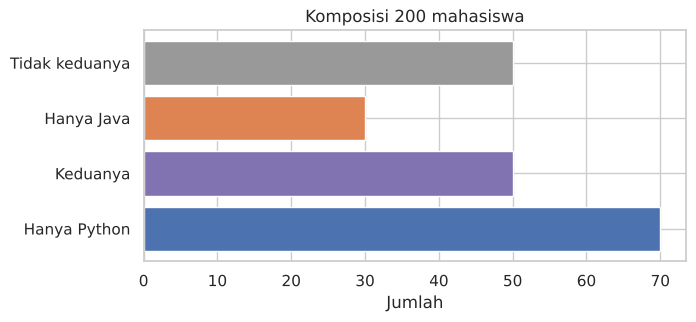

        Besaran   Manual   Python  Selisih
    P(P atau J) 0.750000 0.750000 0.000000
P((P atau J)^c) 0.250000 0.250000 0.000000
   P(P dan J^c) 0.350000 0.350000 0.000000
  P(tepat satu) 0.500000 0.500000 0.000000


In [25]:
S = set(range(1, 201))
python = set(range(1, 121))
java = set(range(71, 151))

P = lambda A: Fraction(len(A), len(S))
print("|Python  dan  Java| =", len(python & java))
print("P(Python  atau  Java)     =", P(python | java), "=", float(P(python | java)))
print("P(tidak keduanya)    =", P(S - (python | java)), "=", float(P(S - (python | java))))
print("P(hanya Python)      =", P(python - java), "=", float(P(python - java)))
print("P(tepat satu bahasa) =", P(python ^ java), "=", float(P(python ^ java)))

bagian = {"Hanya Python": len(python - java), "Keduanya": len(python & java),
          "Hanya Java": len(java - python), "Tidak keduanya": len(S - (python | java))}
plt.figure(figsize=(7, 3))
plt.barh(list(bagian), list(bagian.values()), color=["#4c72b0", "#8172b2", "#dd8452", "#999"])
plt.title("Komposisi 200 mahasiswa"); plt.xlabel("Jumlah"); plt.show()

tabel_banding([("P(P atau J)", (120+80-50)/200, float(P(python | java))),
               ("P((P atau J)^c)", 1-0.75, float(P(S - (python | java)))),
               ("P(P dan J^c)", 70/200, float(P(python - java))),
               ("P(tepat satu)", 100/200, float(P(python ^ java)))])

**5. Perbandingan manual vs Python**

Operasi himpunan Python (|, &, -, ^) pada set ID mahasiswa memberi 3/4, 1/4, 7/20, dan 1/2. Semuanya sama persis dengan hitungan manual (selisih 0).

**6. Interpretasi**

Tiga perempat mahasiswa minimal bisa satu dari dua bahasa ini, tapi masih ada 25% (50 orang) yang belum menguasai keduanya. Ini bisa jadi dasar buat bikin kelas pelatihan tambahan.

**7. Kesimpulan**

Prinsip inklusi-eksklusi dan komplemen langsung bisa diterjemahkan ke operasi set Python dan hasilnya identik.

## Soal P5 - Probabilitas Bersyarat (Build CI Gagal)

**1. Soal**

Dari 1000 build CI: 200 berasal dari commit besar (>500 baris) dan 80 di antaranya gagal; 800 dari commit kecil dan 100 di antaranya gagal. Tentukan P(gagal | besar), P(gagal | kecil), dan P(besar | gagal).

**2. Penyelesaian manual**

- Rumus: P(A|B) = P(A dan B)/P(B)
- P(gagal | besar) = 80/200 = 0,4
- P(gagal | kecil) = 100/800 = 0,125
- Total gagal = 80 + 100 = 180 -> P(besar | gagal) = 80/180 = 4/9 = 0,444444

**3. Kode Python** (hasil eksekusi di bawah sel = **4. Output**)

In [26]:
data = {("besar", "gagal"): 80, ("besar", "sukses"): 120,
        ("kecil", "gagal"): 100, ("kecil", "sukses"): 700}
total = sum(data.values())
besar = data[("besar", "gagal")] + data[("besar", "sukses")]
kecil = data[("kecil", "gagal")] + data[("kecil", "sukses")]
gagal = data[("besar", "gagal")] + data[("kecil", "gagal")]

p_g_besar = Fraction(data[("besar", "gagal")], besar)
p_g_kecil = Fraction(data[("kecil", "gagal")], kecil)
p_besar_g = Fraction(data[("besar", "gagal")], gagal)
print("P(gagal | besar) =", p_g_besar, "=", float(p_g_besar))
print("P(gagal | kecil) =", p_g_kecil, "=", float(p_g_kecil))
print("P(besar | gagal) =", p_besar_g, "=", round(float(p_besar_g), 6))

np.random.seed(42)
N = 200_000
is_besar = np.random.rand(N) < besar / total
is_gagal = np.where(is_besar, np.random.rand(N) < 0.4, np.random.rand(N) < 0.125)
print("\nSimulasi P(gagal | besar) =", round(is_gagal[is_besar].mean(), 6))
print("Simulasi P(besar | gagal) =", round(is_besar[is_gagal].mean(), 6))

tabel_banding([("P(G|B)", 0.4, float(p_g_besar)), ("P(G|K)", 0.125, float(p_g_kecil)),
               ("P(B|G)", 80/180, float(p_besar_g)),
               ("P(B|G) simulasi", 80/180, is_besar[is_gagal].mean())])

P(gagal | besar) = 2/5 = 0.4
P(gagal | kecil) = 1/8 = 0.125
P(besar | gagal) = 4/9 = 0.444444

Simulasi P(gagal | besar) = 0.400761
Simulasi P(besar | gagal) = 0.447044
        Besaran   Manual   Python  Selisih
         P(G|B) 0.400000 0.400000 0.000000
         P(G|K) 0.125000 0.125000 0.000000
         P(B|G) 0.444444 0.444444 0.000000
P(B|G) simulasi 0.444444 0.447044 0.002600


**5. Perbandingan manual vs Python**

Fraction memberi 2/5, 1/8, dan 4/9, sama persis dengan manual. Simulasi 200.000 build memberi P(gagal|besar) = 0,400761 dan P(besar|gagal) = 0,447044 (selisih 0,0026) karena galat simulasi.

**6. Interpretasi**

Commit besar punya peluang gagal 3,2 kali lipat dibanding commit kecil (0,4 vs 0,125). Walaupun commit besar cuma 20% dari total, hampir separuh (44%) build yang gagal berasal dari commit besar. Artinya, membiasakan commit kecil bisa menurunkan build gagal.

**7. Kesimpulan**

Peluang bersyarat tidak simetris: P(gagal|besar) tidak sama dengan P(besar|gagal); Python mengonfirmasi kedua nilai tersebut.

## Soal P6 - Kejadian Saling Bebas (Reliabilitas Server)

**1. Soal**

(a) Pada pelemparan dua dadu, A = dadu pertama genap dan B = jumlah mata dadu 7. Apakah A dan B saling bebas? (b) Tiga server independen memiliki availability 0,90; 0,95; 0,99. Hitung peluang sistem hidup jika disusun seri (semua harus hidup) dan paralel/redundan (cukup satu hidup).

**2. Penyelesaian manual**

- (a) P(A) = 18/36 = 1/2; P(B) = 6/36 = 1/6; A dan B = {(2,5),(4,3),(6,1)} -> P(A dan B) = 3/36 = 1/12. Karena P(A)*P(B) = 1/12 = P(A dan B), A dan B saling bebas.
- (b) Asumsi: kegagalan tiap server saling bebas.
- Seri: P = 0,90 x 0,95 x 0,99 = 0,84645
- Paralel: P = 1 - (0,10 x 0,05 x 0,01) = 1 - 0,00005 = 0,99995

**3. Kode Python** (hasil eksekusi di bawah sel = **4. Output**)

In [27]:
ruang = list(itertools.product(range(1, 7), repeat=2))
A = {s for s in ruang if s[0] % 2 == 0}
B = {s for s in ruang if sum(s) == 7}
PA, PB, PAB = (Fraction(len(e), 36) for e in (A, B, A & B))
print(f"P(A)={PA}, P(B)={PB}, P(A dan B)={PAB}, P(A)P(B)={PA*PB} -> saling bebas? {PAB == PA*PB}")

r = np.array([0.90, 0.95, 0.99])
seri = np.prod(r)
paralel = 1 - np.prod(1 - r)
print(f"\nSistem seri    : {seri:.6f}")
print(f"Sistem paralel : {paralel:.6f}")

np.random.seed(42)
hidup = np.random.rand(1_000_000, 3) < r
print(f"Simulasi seri    : {hidup.all(axis=1).mean():.6f}")
print(f"Simulasi paralel : {hidup.any(axis=1).mean():.6f}")

tabel_banding([("Seri", 0.9*0.95*0.99, hidup.all(axis=1).mean()),
               ("Paralel", 1-0.1*0.05*0.01, hidup.any(axis=1).mean())])

P(A)=1/2, P(B)=1/6, P(A dan B)=1/12, P(A)P(B)=1/12 -> saling bebas? True

Sistem seri    : 0.846450
Sistem paralel : 0.999950


Simulasi seri    : 0.846459


Simulasi paralel : 0.999947
Besaran   Manual   Python  Selisih
   Seri 0.846450 0.846459 0.000009
Paralel 0.999950 0.999947 0.000003


**5. Perbandingan manual vs Python**

Enumerasi itertools.product membuktikan P(A dan B) = P(A)P(B) = 1/12 (True). Untuk server, numpy memberi 0,846450 dan 0,999950 (sama dengan manual); simulasi 1 juta hari memberi 0,846459 dan 0,999947, selisihnya sangat kecil (< 0,00001).

**6. Interpretasi**

Kalau server disusun seri, sistem cuma hidup sekitar 84,6% waktu, jauh lebih buruk dari server terlemahnya. Kalau disusun redundan, availability naik jadi 99,995% ("four nines" lebih). Ini alasan kenapa sistem produksi pakai redundansi.

**7. Kesimpulan**

Untuk kejadian saling bebas, peluang irisan = hasil kali peluang; prinsip ini langsung dipakai untuk menghitung reliabilitas sistem seri dan paralel.

## Soal P7 - Aturan Perkalian & Penjumlahan (Chip Cacat)

**1. Soal**

Sebuah kotak berisi 10 chip, 3 di antaranya cacat. Diambil 2 chip secara acak TANPA pengembalian. Hitung P(keduanya cacat) dan P(tepat satu cacat).

**2. Penyelesaian manual**

- Aturan perkalian (bersyarat): P(C1 dan C2) = P(C1)*P(C2|C1) = 3/10 x 2/9 = 6/90 = 1/15 = 0,066667
- Tepat satu cacat terjadi lewat dua jalur yang saling lepas (aturan penjumlahan):
- P = P(C1B2) + P(B1C2) = 3/10 x 7/9 + 7/10 x 3/9 = 21/90 + 21/90 = 42/90 = 7/15 = 0,466667
- Cek: P(0 cacat) = 7/10 x 6/9 = 7/15, total 1/15 + 7/15 + 7/15 = 1 (sesuai)

**3. Kode Python** (hasil eksekusi di bawah sel = **4. Output**)

In [28]:
chip = ["C"] * 3 + ["B"] * 7

pasang = list(itertools.combinations(range(10), 2))
p2 = Fraction(sum(chip[i] == "C" and chip[j] == "C" for i, j in pasang), len(pasang))
p1 = Fraction(sum((chip[i] == "C") != (chip[j] == "C") for i, j in pasang), len(pasang))
p0 = Fraction(sum(chip[i] == "B" and chip[j] == "B" for i, j in pasang), len(pasang))
print("P(2 cacat)       =", p2, "=", round(float(p2), 6))
print("P(tepat 1 cacat) =", p1, "=", round(float(p1), 6))
print("P(0 cacat)       =", p0, "=", round(float(p0), 6), "| total =", p0 + p1 + p2)

p2_kali = Fraction(3, 10) * Fraction(2, 9)
p1_kali = Fraction(3, 10) * Fraction(7, 9) + Fraction(7, 10) * Fraction(3, 9)
print("Aturan perkalian: P(2 cacat) =", p2_kali, "| P(tepat 1) =", p1_kali)

random.seed(42)
N = 100_000
hasil = Counter(random.sample(chip, 2).count("C") for _ in range(N))
print("Simulasi:", {k: hasil[k] / N for k in sorted(hasil)})

tabel_banding([("P(2 cacat)", 1/15, float(p2)), ("P(tepat 1)", 7/15, float(p1)),
               ("P(2 cacat) simulasi", 1/15, hasil[2] / N), ("P(tepat 1) simulasi", 7/15, hasil[1] / N)])

P(2 cacat)       = 1/15 = 0.066667
P(tepat 1 cacat) = 7/15 = 0.466667
P(0 cacat)       = 7/15 = 0.466667 | total = 1
Aturan perkalian: P(2 cacat) = 1/15 | P(tepat 1) = 7/15
Simulasi: {0: 0.46374, 1: 0.46857, 2: 0.06769}
            Besaran   Manual   Python  Selisih
         P(2 cacat) 0.066667 0.066667 0.000000
         P(tepat 1) 0.466667 0.466667 0.000000
P(2 cacat) simulasi 0.066667 0.067690 0.001023
P(tepat 1) simulasi 0.466667 0.468570 0.001903


**5. Perbandingan manual vs Python**

Enumerasi 45 pasangan (itertools.combinations) dan aturan perkalian dengan Fraction memberi 1/15 dan 7/15, sama persis dengan manual. Simulasi random.sample memberi 0,06769 dan 0,46857 (selisih = 0,001-0,002, galat simulasi).

**6. Interpretasi**

Peluang dua chip yang diambil sama-sama cacat cuma sekitar 6,7%, tapi peluang minimal satu cacat lumayan besar, 1 - 7/15 = 53%. Jadi pemeriksaan acak 2 chip sudah cukup sering menemukan cacat di kotak ini.

**7. Kesimpulan**

Aturan perkalian dipakai untuk kejadian berurutan (bersyarat) dan aturan penjumlahan untuk jalur yang saling lepas; enumerasi Python membuktikan keduanya.

## Soal P8 - Hukum Probabilitas Total (Error Data Center)

**1. Soal**

Trafik sebuah aplikasi dibagi ke data center A, B, C sebesar 50%, 30%, 20%. Peluang request error di masing-masing adalah 1%, 2%, 3%. (a) Berapa peluang sebuah request error? (b) Jika ada request error, data center mana yang paling mungkin jadi penyebabnya?

**2. Penyelesaian manual**

- Partisi ruang sampel: A, B, C saling lepas dan lengkap.
- (a) P(E) = P(A)P(E|A) + P(B)P(E|B) + P(C)P(E|C) = 0,5*0,01 + 0,3*0,02 + 0,2*0,03 = 0,005 + 0,006 + 0,006 = 0,017
- (b) Bayes: P(A|E) = 0,005/0,017 = 0,294118; P(B|E) = 0,006/0,017 = 0,352941; P(C|E) = 0,352941

**3. Kode Python** (hasil eksekusi di bawah sel = **4. Output**)

In [29]:
dc = ["A", "B", "C"]
p_dc = np.array([0.50, 0.30, 0.20])
p_err = np.array([0.01, 0.02, 0.03])

p_total = np.sum(p_dc * p_err)
print("P(error) =", round(p_total, 6))

posterior = p_dc * p_err / p_total
for d, q in zip(dc, posterior):
    print(f"P({d} | error) = {q:.6f}")

np.random.seed(42)
N = 1_000_000
asal = np.random.choice(3, size=N, p=p_dc)
error = np.random.rand(N) < p_err[asal]
print("\nSimulasi P(error) =", error.mean())
print("Simulasi P(C | error) =", round(np.mean(asal[error] == 2), 6))

tabel_banding([("P(error)", 0.017, error.mean()),
               ("P(A|error)", 0.005/0.017, np.mean(asal[error] == 0)),
               ("P(C|error)", 0.006/0.017, np.mean(asal[error] == 2))])

P(error) = 0.017
P(A | error) = 0.294118
P(B | error) = 0.352941
P(C | error) = 0.352941



Simulasi P(error) = 0.017135
Simulasi P(C | error) = 0.357806
   Besaran   Manual   Python  Selisih
  P(error) 0.017000 0.017135 0.000135
P(A|error) 0.294118 0.293668 0.000450
P(C|error) 0.352941 0.357806 0.004864


**5. Perbandingan manual vs Python**

numpy menghasilkan P(E) = 0,017 tepat. Simulasi 1 juta request memberi 0,017135 (selisih 0,000135). P(C|E) simulasi 0,357806 vs teori 0,352941; selisihnya agak lebih besar karena hanya +/-17 ribu request error yang dipakai untuk mengestimasi peluang bersyarat itu.

**6. Interpretasi**

Sekitar 1,7% request akan error. Menariknya, walaupun C cuma melayani 20% trafik, kontribusinya ke error sama besar dengan B (35,3%), karena tingkat error-nya paling tinggi. Jadi perbaikan di B dan C lebih berdampak daripada di A.

**7. Kesimpulan**

Hukum probabilitas total menggabungkan peluang bersyarat dari tiap partisi; hasil teori dan simulasi konsisten.

## Soal P9 - Teorema Bayes (Filter Spam)

**1. Soal**

30% email adalah spam. Kata "gratis" muncul pada 60% spam dan 5% email biasa (ham). Kata "klik" muncul pada 50% spam dan 10% ham. Hitung (a) P(spam | "gratis") dan (b) P(spam | "gratis" dan "klik") dengan asumsi Naive Bayes.

**2. Penyelesaian manual**

- (a) P(S|G) = P(S)P(G|S) / [P(S)P(G|S) + P(H)P(G|H)] = 0,3*0,6 / (0,18 + 0,7*0,05) = 0,18/0,215 = 0,837209
- (b) Asumsi Naive Bayes: kata-kata saling bebas bersyarat pada kelas.
- Pembilang = 0,3*0,6*0,5 = 0,09; ham = 0,7*0,05*0,1 = 0,0035
- P(S|G,K) = 0,09/(0,09 + 0,0035) = 0,09/0,0935 = 0,962567

**3. Kode Python** (hasil eksekusi di bawah sel = **4. Output**)

P(spam | 'gratis')         = 0.837209
P(spam | 'gratis','klik')  = 0.962567
Simulasi P(spam | 'gratis')        = 0.835656
Simulasi P(spam | 'gratis','klik') = 0.963232


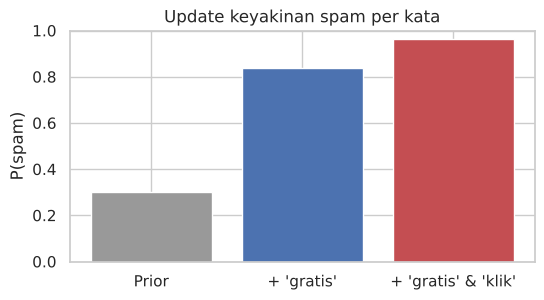

            Besaran   Manual   Python  Selisih
     P(spam|gratis) 0.837209 0.835656 0.001553
P(spam|gratis,klik) 0.962567 0.963232 0.000665


In [30]:
p_spam = 0.30
p_g_s, p_g_h = 0.60, 0.05
p_k_s, p_k_h = 0.50, 0.10

post1 = p_spam * p_g_s / (p_spam * p_g_s + (1 - p_spam) * p_g_h)
num = p_spam * p_g_s * p_k_s
post2 = num / (num + (1 - p_spam) * p_g_h * p_k_h)
print(f"P(spam | 'gratis')         = {post1:.6f}")
print(f"P(spam | 'gratis','klik')  = {post2:.6f}")

np.random.seed(42)
N = 500_000
spam = np.random.rand(N) < p_spam
gratis = np.where(spam, np.random.rand(N) < p_g_s, np.random.rand(N) < p_g_h)
klik = np.where(spam, np.random.rand(N) < p_k_s, np.random.rand(N) < p_k_h)
sim1 = spam[gratis].mean()
sim2 = spam[gratis & klik].mean()
print(f"Simulasi P(spam | 'gratis')        = {sim1:.6f}")
print(f"Simulasi P(spam | 'gratis','klik') = {sim2:.6f}")

plt.figure(figsize=(6, 3))
plt.bar(["Prior", "+ 'gratis'", "+ 'gratis' & 'klik'"], [p_spam, post1, post2], color=["#999", "#4c72b0", "#c44e52"])
plt.ylabel("P(spam)"); plt.title("Update keyakinan spam per kata"); plt.ylim(0, 1); plt.show()

tabel_banding([("P(spam|gratis)", 0.18/0.215, sim1), ("P(spam|gratis,klik)", 0.09/0.0935, sim2)])

**5. Perbandingan manual vs Python**

Rumus di Python memberi 0,837209 dan 0,962567, sama dengan manual. Simulasi 500.000 email memberi 0,835656 dan 0,963232; selisih < 0,002 karena galat simulasi.

**6. Interpretasi**

Satu kata "gratis" saja sudah menaikkan keyakinan spam dari 30% ke 83,7%. Kalau ditambah kata "klik", keyakinan naik lagi ke 96,3%. Inilah cara kerja dasar filter spam Naive Bayes: setiap bukti meng-update peluang.

**7. Kesimpulan**

Teorema Bayes membalik P(kata|spam) menjadi P(spam|kata); penambahan bukti independen membuat posterior makin tajam.

## Soal P10 - Teorema Bayes (Deteksi Malware / Tes Diagnostik)

**1. Soal**

Antivirus mendeteksi malware dengan sensitivitas 95% dan false positive rate 3%. Prevalensi malware di antara file yang dipindai adalah 1%. (a) Jika sebuah file terdeteksi positif, berapa peluang file itu benar-benar malware? (b) Jika file dipindai ulang dengan scanner lain (independen bersyarat) dan positif lagi, berapa peluangnya sekarang?

**2. Penyelesaian manual**

- (a) P(M|+) = 0,01*0,95 / (0,01*0,95 + 0,99*0,03) = 0,0095/(0,0095 + 0,0297) = 0,0095/0,0392 = 95/392 = 0,242347
- (b) Prior baru = 95/392. P(M|+,+) = (95/392*0,95)/(95/392*0,95 + 297/392*0,03) = 90,25/(90,25 + 8,91) = 9025/9916 = 0,910145

**3. Kode Python** (hasil eksekusi di bawah sel = **4. Output**)

Rumus P(M|+) = prev*sens/(fpr*(1 - prev) + prev*sens)
P(M|+) eksak = 95/392 = 0.2423469387755102
P(M|+,+) eksak = 9025/9916 = 0.9101452198467124


Simulasi P(M|+)   = 0.240843
Simulasi P(M|+,+) = 0.906291


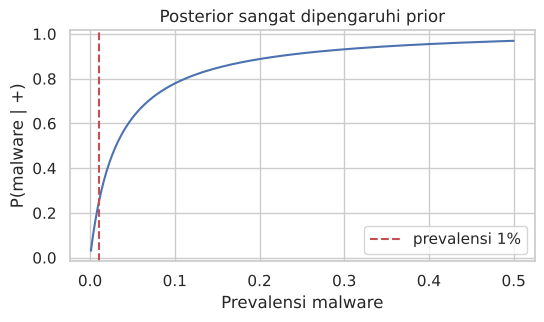

 Besaran   Manual   Python  Selisih
  P(M|+) 0.242347 0.240843 0.001504
P(M|+,+) 0.910145 0.906291 0.003854


In [31]:
prev, sens, fpr = sp.symbols("prev sens fpr", positive=True)
bayes = prev * sens / (prev * sens + (1 - prev) * fpr)
print("Rumus P(M|+) =", bayes)

nilai = {prev: sp.Rational(1, 100), sens: sp.Rational(95, 100), fpr: sp.Rational(3, 100)}
p1 = bayes.subs(nilai)
print("P(M|+) eksak =", p1, "=", float(p1))

p2 = bayes.subs({prev: p1, sens: sp.Rational(95, 100), fpr: sp.Rational(3, 100)})
print("P(M|+,+) eksak =", sp.nsimplify(p2), "=", float(p2))

np.random.seed(42)
N = 1_000_000
malware = np.random.rand(N) < 0.01
t1 = np.where(malware, np.random.rand(N) < 0.95, np.random.rand(N) < 0.03)
t2 = np.where(malware, np.random.rand(N) < 0.95, np.random.rand(N) < 0.03)
print("Simulasi P(M|+)   =", round(malware[t1].mean(), 6))
print("Simulasi P(M|+,+) =", round(malware[t1 & t2].mean(), 6))

f = sp.lambdify(prev, bayes.subs({sens: 0.95, fpr: 0.03}), "numpy")
pv = np.linspace(0.001, 0.5, 300)
plt.figure(figsize=(6, 3))
plt.plot(pv, f(pv)); plt.axvline(0.01, ls="--", c="r", label="prevalensi 1%")
plt.xlabel("Prevalensi malware"); plt.ylabel("P(malware | +)"); plt.legend()
plt.title("Posterior sangat dipengaruhi prior"); plt.show()

tabel_banding([("P(M|+)", 0.0095/0.0392, malware[t1].mean()),
               ("P(M|+,+)", float(p2), malware[t1 & t2].mean())])

**5. Perbandingan manual vs Python**

sympy menurunkan rumus simbolik lalu substitusi memberi pecahan eksak 95/392 dan 9025/9916, sama persis dengan manual. Simulasi 1 juta file memberi 0,240843 dan 0,906291. Selisih (b) = 0,004 lebih besar karena kejadian 'positif dua kali' jumlahnya lebih sedikit (sekitar 9.900 file).

**6. Interpretasi**

Ini hasil yang sering bikin kaget: walaupun scanner-nya 95% akurat, kalau file terdeteksi positif peluang benar-benar malware hanya ~24%. Penyebabnya prevalensi yang sangat rendah, jadi false positive mendominasi. Pemindaian kedua menaikkan keyakinan jadi ~91%. Grafik juga menunjukkan posterior naik drastis seiring prevalensi.

**7. Kesimpulan**

Akurasi tes saja tidak cukup; prior (prevalensi) sangat menentukan posterior, dan pemeriksaan berulang adalah cara efektif mengurangi false alarm.

## Soal P11 - Tabel Kontingensi dengan pandas (OS vs Crash)

**1. Soal**

Data 1000 sesi aplikasi: Android 500 sesi (120 crash), iOS 300 sesi (30 crash), Windows 200 sesi (50 crash). Buat tabel kontingensi, lalu hitung P(Crash), P(Crash | Android), P(iOS | Crash), P(Android dan Crash), dan cek apakah OS dan crash saling bebas.

**2. Penyelesaian manual**

- Total crash = 120 + 30 + 50 = 200 -> P(Crash) = 200/1000 = 0,2
- P(Crash|Android) = 120/500 = 0,24
- P(iOS|Crash) = 30/200 = 0,15
- P(Android dan Crash) = 120/1000 = 0,12
- Cek independensi: P(Android)*P(Crash) = 0,5*0,2 = 0,10 tidak sama dengan 0,12 -> tidak saling bebas

**3. Kode Python** (hasil eksekusi di bawah sel = **4. Output**)

Status   Crash  Tidak  Total
OS                          
Android    120    380    500
Windows     50    150    200
iOS         30    270    300
Total      200    800   1000 

Probabilitas gabungan:
 Status   Crash  Tidak
OS                   
Android   0.12   0.38
Windows   0.05   0.15
iOS       0.03   0.27 



P(Crash)=0.2000 | P(Crash|Android)=0.2400 | P(iOS|Crash)=0.1500
P(Android dan Crash)=0.1200 vs P(Android)P(Crash)=0.1000
Chi-square = 26.8750, dof = 2, p-value = 0.000001


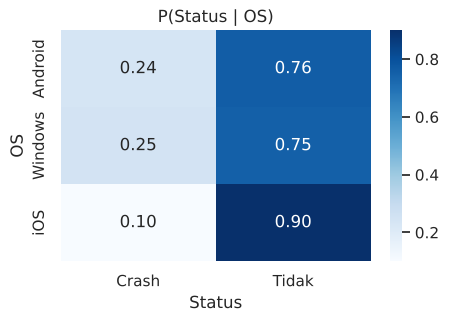

             Besaran   Manual   Python  Selisih
            P(Crash) 0.200000 0.200000 0.000000
    P(Crash|Android) 0.240000 0.240000 0.000000
        P(iOS|Crash) 0.150000 0.150000 0.000000
P(Android dan Crash) 0.120000 0.120000 0.000000


In [32]:
jumlah = {("Android", "Crash"): 120, ("Android", "Tidak"): 380,
          ("iOS", "Crash"): 30, ("iOS", "Tidak"): 270,
          ("Windows", "Crash"): 50, ("Windows", "Tidak"): 150}
baris = [(os_, st) for (os_, st), k in jumlah.items() for _ in range(k)]
df = pd.DataFrame(baris, columns=["OS", "Status"])

tab = pd.crosstab(df["OS"], df["Status"], margins=True, margins_name="Total")
print(tab, "\n")
print("Probabilitas gabungan:\n", pd.crosstab(df["OS"], df["Status"], normalize="all"), "\n")

p_crash = (df["Status"] == "Crash").mean()
p_crash_android = pd.crosstab(df["OS"], df["Status"], normalize="index").loc["Android", "Crash"]
p_ios_crash = pd.crosstab(df["OS"], df["Status"], normalize="columns").loc["iOS", "Crash"]
p_and_crash = ((df["OS"] == "Android") & (df["Status"] == "Crash")).mean()
p_and = (df["OS"] == "Android").mean()
print(f"P(Crash)={p_crash:.4f} | P(Crash|Android)={p_crash_android:.4f} | P(iOS|Crash)={p_ios_crash:.4f}")
print(f"P(Android dan Crash)={p_and_crash:.4f} vs P(Android)P(Crash)={p_and*p_crash:.4f}")

chi2, pval, dof, _ = stats.chi2_contingency(pd.crosstab(df["OS"], df["Status"]))
print(f"Chi-square = {chi2:.4f}, dof = {dof}, p-value = {pval:.6f}")

plt.figure(figsize=(5, 3))
sns.heatmap(pd.crosstab(df["OS"], df["Status"], normalize="index"), annot=True, fmt=".2f", cmap="Blues")
plt.title("P(Status | OS)"); plt.show()

tabel_banding([("P(Crash)", 0.2, p_crash), ("P(Crash|Android)", 0.24, p_crash_android),
               ("P(iOS|Crash)", 0.15, p_ios_crash), ("P(Android dan Crash)", 0.12, p_and_crash)])

**5. Perbandingan manual vs Python**

pd.crosstab dengan opsi normalize='all'/'index'/'columns' memberi 0,20; 0,24; 0,15; 0,12, sama persis dengan manual. Uji chi-square (scipy) memberi chi-square = 26,875 dengan p-value = 0,000001, mendukung kesimpulan bahwa OS dan crash tidak independen.

**6. Interpretasi**

Aplikasi di Android crash 24%, Windows 25%, sedangkan iOS cuma 10%. Karena P(Android dan Crash) lebih besar dari hasil kali marginalnya dan uji chi-square sangat signifikan, tim developer sebaiknya memprioritaskan debugging di Android dan Windows.

**7. Kesimpulan**

pandas.crosstab mempermudah membaca peluang gabungan, marginal, dan bersyarat dari data mentah, dan hasilnya sesuai hitungan manual.

## Soal P12 - Simulasi Monte Carlo (Packet Loss) + Grafik Konvergensi

**1. Soal**

Sebuah pesan dikirim dalam 5 paket. Setiap paket hilang dengan peluang 0,1 secara independen. Estimasi peluang minimal satu paket hilang menggunakan simulasi Monte Carlo, bandingkan dengan teori, dan tunjukkan konvergensinya.

**2. Penyelesaian manual**

- Asumsi: kehilangan antarpaket saling bebas.
- P(minimal 1 hilang) = 1 - P(semua sampai) = 1 - 0,9^5 = 1 - 0,59049 = 0,40951
- Galat standar Monte Carlo = akar(p(1-p)/N) = akar(0,40951*0,59049/100000) = 0,00156

**3. Kode Python** (hasil eksekusi di bawah sel = **4. Output**)

Teori P(minimal 1 paket hilang) = 0.409510


Monte Carlo (N=100,000) = 0.411360  (SE = 0.001556)
Selang 95% simulasi: [0.40831, 0.41441]


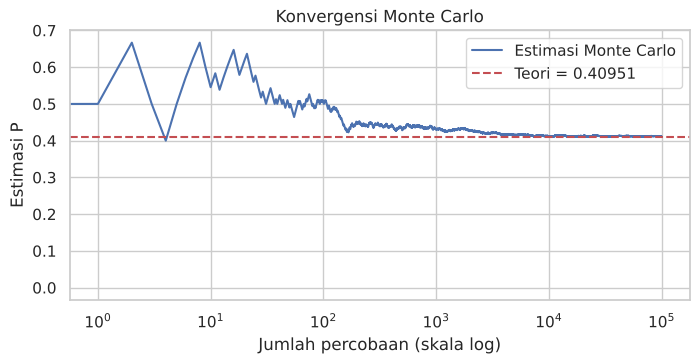

N=    100: estimasi=0.51000, galat=0.10049
N=  1,000: estimasi=0.43100, galat=0.02149
N= 10,000: estimasi=0.41240, galat=0.00289
N=100,000: estimasi=0.41136, galat=0.00185
      Besaran   Manual   Python  Selisih
P(>=1 hilang) 0.409510 0.411360 0.001850


In [33]:
p_loss, n_paket = 0.1, 5
teori = 1 - (1 - p_loss) ** n_paket
print(f"Teori P(minimal 1 paket hilang) = {teori:.6f}")

np.random.seed(42)
N = 100_000
hilang = np.random.rand(N, n_paket) < p_loss
kejadian = hilang.any(axis=1)
estimasi = kejadian.mean()
se = np.sqrt(estimasi * (1 - estimasi) / N)
print(f"Monte Carlo (N={N:,}) = {estimasi:.6f}  (SE = {se:.6f})")
print(f"Selang 95% simulasi: [{estimasi-1.96*se:.5f}, {estimasi+1.96*se:.5f}]")

jalan = np.cumsum(kejadian) / np.arange(1, N + 1)
plt.figure(figsize=(8, 3.5))
plt.plot(jalan, label="Estimasi Monte Carlo")
plt.axhline(teori, color="r", ls="--", label=f"Teori = {teori:.5f}")
plt.xscale("log"); plt.xlabel("Jumlah percobaan (skala log)"); plt.ylabel("Estimasi P")
plt.title("Konvergensi Monte Carlo"); plt.legend(); plt.show()

for m in [100, 1_000, 10_000, 100_000]:
    print(f"N={m:>7,}: estimasi={jalan[m-1]:.5f}, galat={abs(jalan[m-1]-teori):.5f}")

tabel_banding([("P(>=1 hilang)", 1 - 0.9**5, estimasi)])

**5. Perbandingan manual vs Python**

Monte Carlo dengan N = 100.000 memberi 0,41136, selisih 0,00185 dari teori (sekitar 1,2 SE) dan nilai teori masih berada di dalam selang 95% simulasi [0,40831; 0,41441]. Pada N = 100 galatnya 0,10, N = 1.000 galatnya 0,021, N = 10.000 galatnya 0,0029; galat turun kira-kira sebanding 1/akar N.

**6. Interpretasi**

Sekitar 41% pesan butuh retransmisi minimal satu paket. Grafik konvergensi memperlihatkan estimasi awalnya naik-turun liar lalu makin stabil di sekitar garis teori, sesuai hukum bilangan besar.

**7. Kesimpulan**

Monte Carlo bisa mengestimasi peluang tanpa rumus, dan akurasinya meningkat seiring banyaknya percobaan (galat sebanding dengan 1/akar N).

## Soal P13 - Birthday Problem & Tabrakan Hash (hashlib)

**1. Soal**

(a) Berapa peluang minimal dua orang dari 23 orang berulang tahun sama? (b) Sebuah sistem memakai hash 16-bit (65.536 nilai) untuk 300 data. Berapa peluang terjadi minimal satu tabrakan hash? Verifikasi dengan simulasi MD5 sungguhan.

**2. Penyelesaian manual**

- Asumsi: nilai (ultah/hash) tersebar seragam dan independen.
- P(tabrakan) = 1 - hasil kali untuk i=0 sampai n-1 dari (N-i)/N
- (a) N = 365, n = 23 -> P = 1 - (365*364*...*343)/365^23 = 0,507297
- (b) Aproksimasi: P = 1 - exp(-n(n-1)/(2N)) = 1 - exp(-300*299/131072) = 1 - exp(-0,68436) = 0,495585

**3. Kode Python** (hasil eksekusi di bawah sel = **4. Output**)

P(ada ultah sama, 23 orang) = 0.507297
Hash 16-bit, n=300: eksak = 0.496112, aproksimasi = 0.495585


Simulasi MD5 16-bit: 0.5045


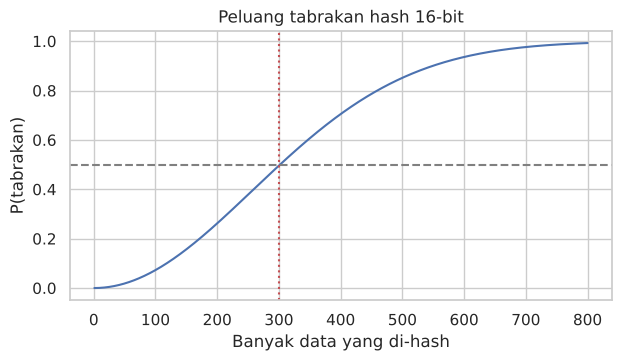

n minimal agar P(tabrakan) >= 0.5: 302
               Besaran   Manual   Python  Selisih
        Ultah 23 orang 0.507297 0.507297 0.000000
  Hash eksak vs aproks 0.495585 0.496112 0.000527
Hash eksak vs simulasi 0.496112 0.504500 0.008388


In [34]:
def p_tabrakan(n, N):
    return 1 - np.prod((N - np.arange(n)) / N)

print(f"P(ada ultah sama, 23 orang) = {p_tabrakan(23, 365):.6f}")

N, n = 2 ** 16, 300
eksak = p_tabrakan(n, N)
aprox = 1 - math.exp(-n * (n - 1) / (2 * N))
print(f"Hash 16-bit, n=300: eksak = {eksak:.6f}, aproksimasi = {aprox:.6f}")

random.seed(42)
percobaan, tabrak = 2000, 0
for t in range(percobaan):
    hs = {int(hashlib.md5(f"{t}-{random.random()}".encode()).hexdigest()[:4], 16) for _ in range(n)}
    tabrak += len(hs) < n
print(f"Simulasi MD5 16-bit: {tabrak/percobaan:.4f}")

ns = np.arange(1, 801)
plt.figure(figsize=(7, 3.5))
plt.plot(ns, [p_tabrakan(k, N) for k in ns])
plt.axhline(0.5, ls="--", c="gray"); plt.axvline(300, ls=":", c="r")
plt.xlabel("Banyak data yang di-hash"); plt.ylabel("P(tabrakan)")
plt.title("Peluang tabrakan hash 16-bit"); plt.show()
print("n minimal agar P(tabrakan) >= 0.5:", int(ns[np.argmax([p_tabrakan(k, N) >= 0.5 for k in ns])]))

tabel_banding([("Ultah 23 orang", 0.507297, p_tabrakan(23, 365)),
               ("Hash eksak vs aproks", aprox, eksak), ("Hash eksak vs simulasi", eksak, tabrak / percobaan)])

**5. Perbandingan manual vs Python**

Rumus eksak di numpy memberi 0,507297 (ultah) dan 0,496112 (hash), sedangkan aproksimasi eksponensial 0,495585 (selisih 0,0005). Simulasi 2000 percobaan memakai 16 bit pertama MD5 memberi 0,5045; selisih 0,0084 masih di bawah 1 galat standar (akar(0,25/2000) = 0,011), jadi wajar.

**6. Interpretasi**

Cuma dengan 23 orang, peluang ada ultah kembar sudah lebih dari 50%. Untuk hash 16-bit, cukup sekitar 302 data agar peluang tabrakan >= 50%, padahal ruang nilainya 65.536. Ini alasan kenapa hash untuk keamanan butuh panjang bit besar (sekitar akar N data sudah bikin tabrakan).

**7. Kesimpulan**

Birthday paradox menunjukkan tabrakan terjadi jauh lebih cepat dari intuisi; MD5 sungguhan berperilaku sesuai model hash acak seragam.

## Soal P14 - Monty Hall (Simulasi)

**1. Soal**

Ada 3 pintu, satu berisi mobil. Peserta memilih satu pintu, lalu host (yang tahu letak mobil) membuka satu pintu lain yang berisi kambing. Peserta boleh tetap atau menukar pilihan. Strategi mana yang lebih baik? Buktikan dengan simulasi 100.000 permainan.

**2. Penyelesaian manual**

- Asumsi: mobil ditempatkan acak, host selalu membuka pintu kambing yang bukan pilihan peserta.
- Strategi tetap menang hanya jika pilihan awal benar: P = 1/3
- Strategi tukar menang jika pilihan awal salah (peluang 2/3), karena host sudah 'membuang' satu kambing: P = 2/3

**3. Kode Python** (hasil eksekusi di bawah sel = **4. Output**)

P(menang | tetap) = 0.33252  (teori 1/3 = 0.33333)
P(menang | tukar) = 0.66748  (teori 2/3 = 0.66667)


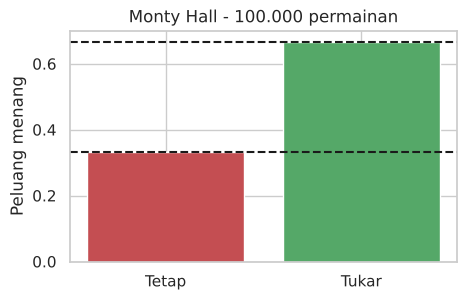

Besaran   Manual   Python  Selisih
  Tetap 0.333333 0.332520 0.000813
  Tukar 0.666667 0.667480 0.000813


In [35]:
random.seed(42)
N = 100_000
menang_tetap = menang_tukar = 0
for _ in range(N):
    mobil = random.randint(0, 2)
    pilih = random.randint(0, 2)
    buka = random.choice([d for d in range(3) if d != pilih and d != mobil])
    tukar = next(d for d in range(3) if d != pilih and d != buka)
    menang_tetap += (pilih == mobil)
    menang_tukar += (tukar == mobil)

print(f"P(menang | tetap) = {menang_tetap/N:.5f}  (teori 1/3 = {1/3:.5f})")
print(f"P(menang | tukar) = {menang_tukar/N:.5f}  (teori 2/3 = {2/3:.5f})")

plt.figure(figsize=(5, 3))
plt.bar(["Tetap", "Tukar"], [menang_tetap / N, menang_tukar / N], color=["#c44e52", "#55a868"])
plt.axhline(1/3, ls="--", c="k"); plt.axhline(2/3, ls="--", c="k")
plt.ylabel("Peluang menang"); plt.title("Monty Hall - 100.000 permainan"); plt.show()

tabel_banding([("Tetap", 1/3, menang_tetap / N), ("Tukar", 2/3, menang_tukar / N)])

**5. Perbandingan manual vs Python**

Simulasi memberi P(menang|tetap) = 0,33252 dan P(menang|tukar) = 0,66748. Selisih dari 1/3 dan 2/3 hanya 0,0008 (galat simulasi).

**6. Interpretasi**

Menukar pintu menggandakan peluang menang. Kuncinya, host tidak membuka pintu secara acak; informasi dari host membuat peluang 2/3 'berpindah' ke pintu yang tersisa.

**7. Kesimpulan**

Simulasi membuktikan hasil yang kontra-intuitif: strategi tukar menang 2/3, strategi tetap hanya 1/3.

## Soal P15 - Nilai Harapan (Biaya Downtime Harian)

**1. Soal**

Dalam sehari, server tidak mengalami gangguan dengan peluang 0,7 (biaya 0), satu gangguan dengan peluang 0,2 (biaya Rp5 juta), dan dua gangguan dengan peluang 0,1 (biaya Rp12 juta). Hitung nilai harapan dan varians biaya, lalu putuskan apakah asuransi SLA seharga Rp2,5 juta/hari menguntungkan secara rata-rata.

**2. Penyelesaian manual**

- E[X] = jumlah x*p(x) = 0*0,7 + 5*0,2 + 12*0,1 = 0 + 1 + 1,2 = 2,2 juta
- E[X^2] = 0 + 25*0,2 + 144*0,1 = 5 + 14,4 = 19,4
- Var(X) = E[X^2] - (E[X])^2 = 19,4 - 4,84 = 14,56; SD = akar(14,56) = 3,8158 juta

**3. Kode Python** (hasil eksekusi di bawah sel = **4. Output**)

In [36]:
biaya = [0, 5, 12]
peluang = [0.7, 0.2, 0.1]

E = sum(b * p for b, p in zip(biaya, peluang))
E2 = sum(b**2 * p for b, p in zip(biaya, peluang))
Var = E2 - E**2
print(f"E[X] = {E:.4f} juta | Var(X) = {Var:.4f} | SD = {math.sqrt(Var):.4f}")

random.seed(42)
hari = random.choices(biaya, weights=peluang, k=100_000)
print(f"Simulasi: mean = {statistics.mean(hari):.4f}, pvariance = {statistics.pvariance(hari):.4f}")
print("Frekuensi relatif:", {k: v / len(hari) for k, v in sorted(Counter(hari).items())})

premi = 2.5
print(f"Premi {premi} juta {'>' if premi > E else '<'} E[biaya] {E:.2f} juta")

tabel_banding([("E[X]", 2.2, statistics.mean(hari)), ("Var(X)", 14.56, statistics.pvariance(hari))])

E[X] = 2.2000 juta | Var(X) = 14.5600 | SD = 3.8158
Simulasi: mean = 2.2047, pvariance = 14.6266
Frekuensi relatif: {0: 0.70012, 5: 0.19912, 12: 0.10076}
Premi 2.5 juta > E[biaya] 2.20 juta
Besaran    Manual    Python  Selisih
   E[X]  2.200000  2.204720 0.004720
 Var(X) 14.560000 14.626650 0.066650


**5. Perbandingan manual vs Python**

Rumus di Python memberi E = 2,2 dan Var = 14,56 (sama). Simulasi 100.000 hari dengan random.choices + statistics memberi mean 2,2047 dan varians 14,6266; selisih kecil karena galat simulasi.

**6. Interpretasi**

Rata-rata kerugian sekitar Rp2,2 juta per hari, lebih kecil dari premi Rp2,5 juta. Jadi secara nilai harapan asuransi itu tidak menguntungkan. Tapi SD-nya besar (sekitar Rp3,8 juta), jadi kalau perusahaan tidak tahan risiko kerugian Rp12 juta dalam sehari, asuransi masih bisa dipertimbangkan.

**7. Kesimpulan**

Nilai harapan memberi gambaran rata-rata jangka panjang, sedangkan varians menunjukkan risikonya; keputusan sebaiknya memperhatikan keduanya.

## Soal P16 - Peluang Geometris (Dua Request dalam 60 Detik)

**1. Soal**

Dua request datang secara acak dan independen dalam rentang 0-60 detik (masing-masing Uniform(0, 60)). Kedua request dianggap bentrok jika selisih waktunya kurang dari 10 detik. Berapa peluang terjadi bentrok?

**2. Penyelesaian manual**

- Ruang sampel = persegi 60 x 60 = 3600
- Daerah tidak bentrok (|X-Y| >= 10) = dua segitiga siku-siku dengan sisi 50: 2 x 1/2 x 50 x 50 = 2500
- P(bentrok) = 1 - 2500/3600 = 1 - (50/60)^2 = 11/36 = 0,305556

**3. Kode Python** (hasil eksekusi di bawah sel = **4. Output**)

Teori (geometri)  = 0.305556
Integral dblquad  = 0.305556
Monte Carlo       = 0.307700


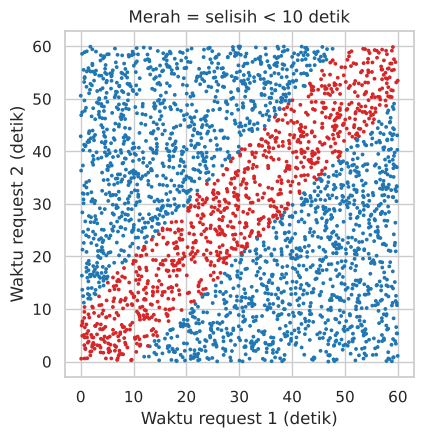

             Besaran   Manual   Python  Selisih
P(|X-Y|<10) integral 0.305556 0.305556 0.000000
          P simulasi 0.305556 0.307700 0.002144


In [37]:
teori = 1 - (50 / 60)**2

luas, _ = integrate.dblquad(lambda y, x: 1 / 3600, 0, 60, lambda x: max(0, x - 10), lambda x: min(60, x + 10))
print(f"Teori (geometri)  = {teori:.6f}")
print(f"Integral dblquad  = {luas:.6f}")

np.random.seed(42)
X, Y = np.random.uniform(0, 60, 100_000), np.random.uniform(0, 60, 100_000)
bentrok = np.abs(X - Y) < 10
print(f"Monte Carlo       = {bentrok.mean():.6f}")

plt.figure(figsize=(4.5, 4.5))
plt.scatter(X[:3000], Y[:3000], s=3, c=np.where(bentrok[:3000], "tab:red", "tab:blue"))
plt.xlabel("Waktu request 1 (detik)"); plt.ylabel("Waktu request 2 (detik)")
plt.title("Merah = selisih < 10 detik"); plt.show()

tabel_banding([("P(|X-Y|<10) integral", 11/36, luas), ("P simulasi", 11/36, bentrok.mean())])

**5. Perbandingan manual vs Python**

Integral ganda scipy.integrate.dblquad atas daerah |x - y| < 10 memberi 0,305556, sama persis dengan hasil geometri. Monte Carlo 100.000 titik memberi 0,3077 (selisih 0,002). Scatter plot memperlihatkan pita diagonal berwarna merah sebagai daerah bentrok.

**6. Interpretasi**

Peluang dua request bentrok dalam jendela 10 detik sekitar 30,6%. Kalau server hanya bisa memproses satu request per 10 detik, hampir sepertiga kasus akan ada antrian.

**7. Kesimpulan**

Peluang untuk variabel kontinu dapat dihitung sebagai perbandingan luas; integral numerik dan Monte Carlo memberikan hasil yang sama.

## Soal P17 - Distribusi Peluang Gabungan, Kovarians, dan Korelasi

**1. Soal**

X = banyak retry sebuah request (0, 1, 2) dan Y = 1 jika jaringan sedang lambat (0 jika tidak). Distribusi gabungannya: P(0,0)=0,30; P(0,1)=0,10; P(1,0)=0,20; P(1,1)=0,15; P(2,0)=0,10; P(2,1)=0,15. Hitung distribusi marginal, E[X], E[Y], Cov(X,Y), korelasi, P(X >= 1 | Y = 1), Var(X+Y), dan cek apakah X dan Y independen.

**2. Penyelesaian manual**

- Marginal X: P(X=0)=0,40; P(X=1)=0,35; P(X=2)=0,25. Marginal Y: P(Y=0)=0,60; P(Y=1)=0,40
- E[X] = 0,35 + 2(0,25) = 0,85; E[Y] = 0,40
- E[XY] = 1*1*0,15 + 2*1*0,15 = 0,45 -> Cov = 0,45 - 0,85*0,40 = 0,11
- Var(X) = (0,35 + 4*0,25) - 0,85^2 = 1,35 - 0,7225 = 0,6275; Var(Y) = 0,4*0,6 = 0,24
- rho = 0,11/akar(0,6275*0,24) = 0,2835
- P(X>=1 | Y=1) = (0,15 + 0,15)/0,40 = 0,75
- Var(X+Y) = 0,6275 + 0,24 + 2(0,11) = 1,0875
- P(0,0) = 0,30 tidak sama dengan P(X=0)P(Y=0) = 0,24 -> tidak independen

**3. Kode Python** (hasil eksekusi di bawah sel = **4. Output**)

In [38]:
pxy = pd.DataFrame([[0.30, 0.10], [0.20, 0.15], [0.10, 0.15]], index=[0, 1, 2], columns=[0, 1])
pxy.index.name, pxy.columns.name = "X", "Y"
print(pxy, "\n")

x, y = np.array(pxy.index), np.array(pxy.columns)
px, py = pxy.sum(axis=1).values, pxy.sum(axis=0).values
EX, EY = (x * px).sum(), (y * py).sum()
EXY = sum(i * j * pxy.loc[i, j] for i in x for j in y)
VarX, VarY = (x**2 * px).sum() - EX**2, (y**2 * py).sum() - EY**2
cov = EXY - EX * EY
print("Marginal X:", px, "| Marginal Y:", py)
print(f"E[X]={EX:.4f}, E[Y]={EY:.4f}, E[XY]={EXY:.4f}")
print(f"Var(X)={VarX:.4f}, Var(Y)={VarY:.4f}, Cov(X,Y)={cov:.4f}, Korelasi={cov/np.sqrt(VarX*VarY):.6f}")
print(f"P(X>=1 | Y=1) = {pxy.loc[[1,2], 1].sum() / py[1]:.4f}")
print(f"P(X=0,Y=0)={pxy.loc[0,0]} vs P(X=0)P(Y=0)={px[0]*py[0]:.2f} -> independen? {np.isclose(pxy.loc[0,0], px[0]*py[0])}")
print(f"E[X+Y]={EX+EY:.4f} | Var(X+Y)={VarX + VarY + 2*cov:.4f}")

np.random.seed(42)
idx = np.random.choice(6, size=100_000, p=pxy.values.flatten())
Xs, Ys = idx // 2, idx % 2
print(f"\nSimulasi: Cov={np.cov(Xs, Ys, ddof=0)[0,1]:.4f}, Var(X+Y)={np.var(Xs+Ys):.4f}")

tabel_banding([("E[X]", 0.85, EX), ("Cov(X,Y)", 0.11, cov), ("Cov simulasi", 0.11, np.cov(Xs, Ys, ddof=0)[0, 1]),
               ("Var(X+Y)", 1.0875, VarX + VarY + 2 * cov)])

Y    0     1
X           
0  0.3  0.10
1  0.2  0.15
2  0.1  0.15 

Marginal X: [0.4  0.35 0.25] | Marginal Y: [0.6 0.4]
E[X]=0.8500, E[Y]=0.4000, E[XY]=0.4500
Var(X)=0.6275, Var(Y)=0.2400, Cov(X,Y)=0.1100, Korelasi=0.283452
P(X>=1 | Y=1) = 0.7500
P(X=0,Y=0)=0.3 vs P(X=0)P(Y=0)=0.24 -> independen? False
E[X+Y]=1.2500 | Var(X+Y)=1.0875



Simulasi: Cov=0.1095, Var(X+Y)=1.0855
     Besaran   Manual   Python  Selisih
        E[X] 0.850000 0.850000 0.000000
    Cov(X,Y) 0.110000 0.110000 0.000000
Cov simulasi 0.110000 0.109545 0.000455
    Var(X+Y) 1.087500 1.087500 0.000000


**5. Perbandingan manual vs Python**

Perhitungan pandas/numpy memberi semua angka yang sama dengan manual (E[X]=0,85; Cov=0,11; rho=0,283452; Var(X+Y)=1,0875). Simulasi 100.000 pasangan memberi Cov = 0,1095 dan Var(X+Y) = 1,0855 (galat simulasi).

**6. Interpretasi**

Kovarians positif berarti saat jaringan lambat, retry cenderung lebih banyak: peluang ada retry naik menjadi 75% saat jaringan lambat, dibanding 50% kalau tidak lambat. Karena X dan Y tidak independen, Var(X+Y) tidak sama dengan Var(X) + Var(Y); suku 2Cov harus ikut dihitung.

**7. Kesimpulan**

Distribusi gabungan memberi marginal, peluang bersyarat, dan kovarians; Python mempermudah perhitungan dan verifikasinya.

# C. Distribusi Probabilitas
Tiap soal menghitung peluang, E[X], dan Var(X) secara manual **dan** dengan `scipy.stats`, lalu mensimulasikan 100.000 sampel numpy dan menampilkan grafik PMF/PDF, CDF, serta histogram simulasi yang ditumpuk kurva teori.

## Soal D1 - Distribusi Bernoulli (Status Request API)

**1. Soal**

Sebuah request API berhasil dengan peluang 0,95. Misalkan X = 1 jika sukses dan 0 jika gagal. Hitung P(X=1), E[X], Var(X), lalu simulasikan 100.000 request.

**2. Penyelesaian manual**

- X ~ Bernoulli(p = 0,95); P(X=x) = p^x(1-p)^(1-x)
- P(X=1) = 0,95; P(X=0) = 0,05
- E[X] = p = 0,95
- Var(X) = p(1-p) = 0,95*0,05 = 0,0475

**3. Kode Python** (hasil eksekusi di bawah sel = **4. Output**)

P(X=1) = 0.95 | P(X=0) = 0.05
E[X] = 0.95 | Var(X) = 0.0475
Mean    teori = 0.950000 | simulasi = 0.951290
Varians teori = 0.047500 | simulasi = 0.046337
      Besaran   Manual   Python  Selisih
       P(X=1) 0.950000 0.950000 0.000000
         E[X] 0.950000 0.950000 0.000000
       Var(X) 0.047500 0.047500 0.000000
Mean simulasi 0.950000 0.951290 0.001290


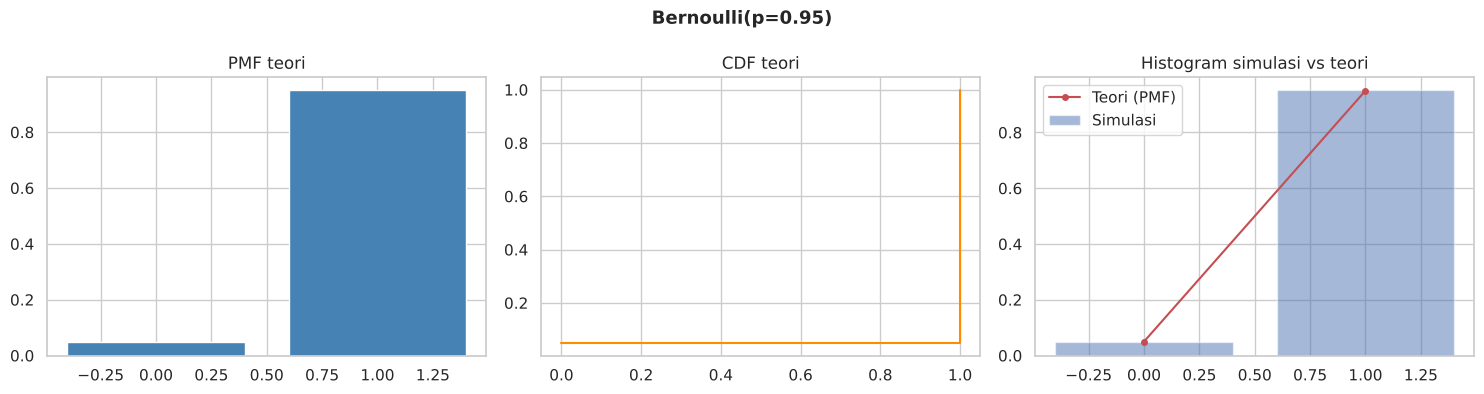

In [39]:
p = 0.95
X = stats.bernoulli(p)

print("P(X=1) =", X.pmf(1), "| P(X=0) =", round(X.pmf(0), 6))
print("E[X] =", X.mean(), "| Var(X) =", round(X.var(), 6))

np.random.seed(42)
sampel = X.rvs(size=100_000)
ringkas_simulasi(sampel, X)

tabel_banding([("P(X=1)", 0.95, X.pmf(1)), ("E[X]", 0.95, X.mean()),
               ("Var(X)", 0.95*0.05, X.var()), ("Mean simulasi", 0.95, sampel.mean())])
plot_distribusi(X, sampel, np.array([0, 1]), "Bernoulli(p=0.95)")

**5. Perbandingan manual vs Python**

scipy.stats.bernoulli memberi P(X=1) = 0,95, E = 0,95, Var = 0,0475 (sama persis). Simulasi 100.000 request: mean 0,95129 dan varians 0,046337, sangat dekat dengan teori.

**6. Interpretasi**

Rata-rata 95 dari 100 request sukses. Varians kecil (0,0475) menandakan hasilnya didominasi sukses. Bernoulli ini jadi 'batu bata' untuk distribusi Binomial, Geometrik, dan Binomial Negatif.

**7. Kesimpulan**

Distribusi Bernoulli memodelkan satu percobaan sukses/gagal dengan E = p dan Var = p(1-p); teori, scipy, dan simulasi konsisten.

## Soal D2 - Distribusi Binomial (Unit Test Gagal)

**1. Soal**

Sebuah suite punya 20 unit test independen, masing-masing gagal dengan peluang 0,1. Misalkan X = banyak test yang gagal. Hitung P(X=2), P(X<=2), P(X>=5), E[X], dan Var(X).

**2. Penyelesaian manual**

- X ~ Binomial(n = 20, p = 0,1); P(X=k) = C(n,k) p^k (1-p)^(n-k)
- P(X=2) = C(20,2)*0,1^2*0,9^18 = 190*0,01*0,150095 = 0,285180
- P(X<=2) = P(0) + P(1) + P(2) = 0,121577 + 0,270170 + 0,285180 = 0,676927
- E[X] = np = 2; Var(X) = np(1-p) = 1,8

**3. Kode Python** (hasil eksekusi di bawah sel = **4. Output**)

P(X=2)  manual=0.285180 | scipy=0.285180
P(X<=2) manual=0.676927 | scipy=0.676927
P(X>=5) scipy =0.043174
E[X] = 2.0 | Var(X) = 1.8
Mean    teori = 2.000000 | simulasi = 1.996240
Varians teori = 1.800000 | simulasi = 1.786766
P(X=2) simulasi = 0.28594
Besaran   Manual   Python  Selisih
 P(X=2) 0.285180 0.285180 0.000000
P(X<=2) 0.676927 0.676927 0.000000
   E[X] 2.000000 2.000000 0.000000
 Var(X) 1.800000 1.800000 0.000000


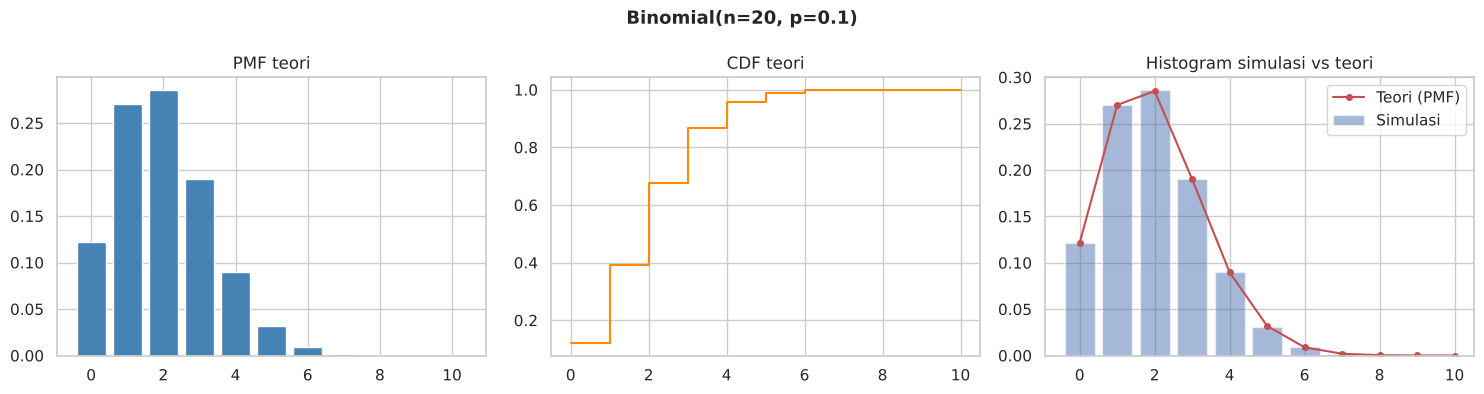

In [40]:
n, p = 20, 0.1
X = stats.binom(n, p)

manual_p2 = math.comb(20, 2) * 0.1**2 * 0.9**18
manual_le2 = sum(math.comb(20, k) * 0.1**k * 0.9**(20 - k) for k in range(3))
print(f"P(X=2)  manual={manual_p2:.6f} | scipy={X.pmf(2):.6f}")
print(f"P(X<=2) manual={manual_le2:.6f} | scipy={X.cdf(2):.6f}")
print(f"P(X>=5) scipy ={X.sf(4):.6f}")
print("E[X] =", X.mean(), "| Var(X) =", X.var())

np.random.seed(42)
sampel = np.random.binomial(n, p, size=100_000)
ringkas_simulasi(sampel, X)
print("P(X=2) simulasi =", np.mean(sampel == 2))

tabel_banding([("P(X=2)", manual_p2, X.pmf(2)), ("P(X<=2)", manual_le2, X.cdf(2)),
               ("E[X]", n*p, X.mean()), ("Var(X)", n*p*(1-p), X.var())])
plot_distribusi(X, sampel, np.arange(0, 11), "Binomial(n=20, p=0.1)")

**5. Perbandingan manual vs Python**

Rumus manual (math.comb) dan scipy.stats.binom memberi angka identik 0,285180 dan 0,676927. P(X>=5) = 0,043174 lewat binom.sf(4). Simulasi: mean 1,99624, varians 1,786766, P(X=2) = 0,28594, semuanya dekat dengan teori.

**6. Interpretasi**

Rata-rata ada 2 test gagal per run. Sekitar 68% run gagal paling banyak 2 test, dan hanya 4,3% run yang gagal 5 test atau lebih. Kalau suatu run tiba-tiba gagal >=5 test, itu kejadian langka yang mengindikasikan ada bug serius, bukan sekadar flaky test.

**7. Kesimpulan**

Binomial cocok untuk menghitung banyak sukses/gagal dari n percobaan Bernoulli independen; manual, scipy, dan simulasi sejalan.

## Soal D3 - Distribusi Geometrik (Login Sampai Berhasil)

**1. Soal**

Seorang pengguna yang lupa password berhasil login dengan peluang 0,3 pada setiap percobaan (independen). Misalkan X = nomor percobaan saat login pertama kali berhasil. Hitung P(X=3), P(X<=3), E[X], Var(X), dan tunjukkan sifat memoryless.

**2. Penyelesaian manual**

- X ~ Geometrik(p = 0,3), X = 1, 2, 3, ...; P(X=k) = (1-p)^(k-1) p
- P(X=3) = 0,7^2*0,3 = 0,147
- P(X<=3) = 1 - 0,7^3 = 1 - 0,343 = 0,657
- E[X] = 1/p = 3,3333; Var(X) = (1-p)/p^2 = 0,7/0,09 = 7,7778
- Memoryless: P(X>5 | X>2) = 0,7^5/0,7^2 = 0,7^3 = P(X>3) = 0,343

**3. Kode Python** (hasil eksekusi di bawah sel = **4. Output**)

P(X=3)  manual=0.147000 | scipy=0.147000
P(X<=3) manual=0.657000 | scipy=0.657000
E[X]=3.333333 | Var(X)=7.777778
P(X>5|X>2)=0.343000 | P(X>3)=0.343000
Mean    teori = 3.333333 | simulasi = 3.322060
Varians teori = 7.777778 | simulasi = 7.666077
Besaran   Manual   Python  Selisih
 P(X=3) 0.147000 0.147000 0.000000
P(X<=3) 0.657000 0.657000 0.000000
   E[X] 3.333333 3.333333 0.000000
 Var(X) 7.777778 7.777778 0.000000


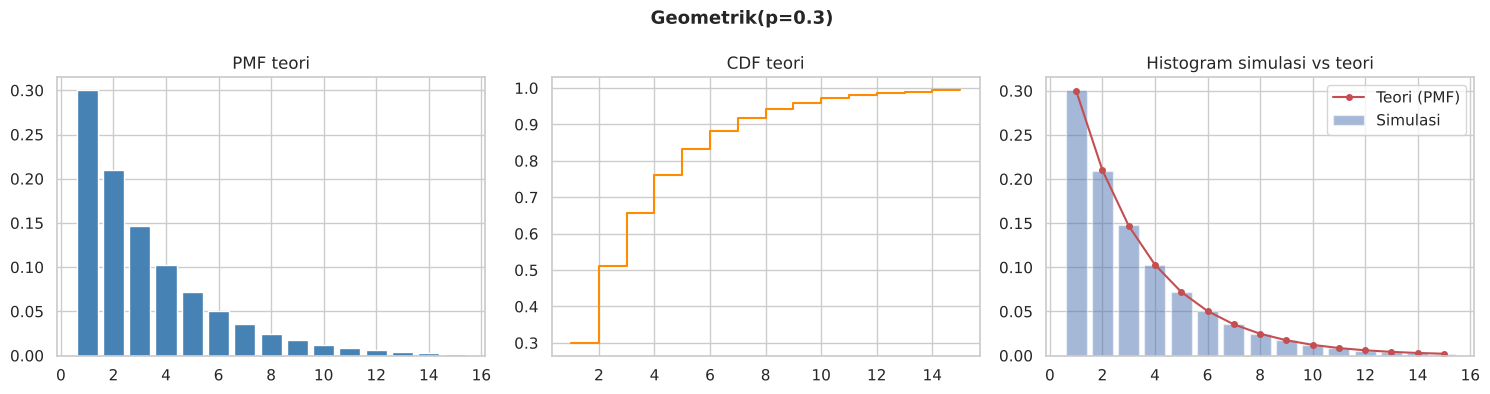

In [41]:
p = 0.3
X = stats.geom(p)

manual_p3 = (1 - p)**2 * p
manual_le3 = 1 - (1 - p)**3
print(f"P(X=3)  manual={manual_p3:.6f} | scipy={X.pmf(3):.6f}")
print(f"P(X<=3) manual={manual_le3:.6f} | scipy={X.cdf(3):.6f}")
print(f"E[X]={X.mean():.6f} | Var(X)={X.var():.6f}")

print(f"P(X>5|X>2)={X.sf(5)/X.sf(2):.6f} | P(X>3)={X.sf(3):.6f}")

np.random.seed(42)
sampel = np.random.geometric(p, size=100_000)
ringkas_simulasi(sampel, X)

tabel_banding([("P(X=3)", 0.147, X.pmf(3)), ("P(X<=3)", 0.657, X.cdf(3)),
               ("E[X]", 1/p, X.mean()), ("Var(X)", (1-p)/p**2, X.var())])
plot_distribusi(X, sampel, np.arange(1, 16), "Geometrik(p=0.3)")

**5. Perbandingan manual vs Python**

scipy.stats.geom memberi nilai identik (0,147; 0,657; 3,3333; 7,7778) dan sifat memoryless terbukti (0,343 = 0,343). Simulasi 100.000: mean 3,32206 dan varians 7,666077; selisih varians sedikit lebih besar karena distribusi ini berekor panjang.

**6. Interpretasi**

Rata-rata pengguna butuh sekitar 3-4 kali percobaan. Sekitar 34% pengguna masih gagal setelah 3 percobaan, jadi kalau sistem mengunci akun setelah 3 kali gagal, cukup banyak pengguna jujur yang akan terkunci.

**7. Kesimpulan**

Distribusi Geometrik memodelkan waktu tunggu sukses pertama dengan E = 1/p dan bersifat memoryless; scipy dan simulasi mengonfirmasi.

## Soal D4 - Distribusi Binomial Negatif (Deploy Sampai 3 Kali Sukses)

**1. Soal**

Tim DevOps butuh 3 deployment sukses ke staging. Setiap deploy sukses dengan peluang 0,6 (independen). Misalkan X = banyak deploy gagal sebelum sukses ke-3. Hitung P(X=2), P(X<=1), E[X], Var(X).

**2. Penyelesaian manual**

- X ~ NB(r = 3, p = 0,6), dengan X = banyak gagal sebelum sukses ke-r (konvensi scipy)
- P(X=k) = C(k+r-1, k) p^r (1-p)^k
- P(X=2) = C(4,2)*0,6^3*0,4^2 = 6*0,216*0,16 = 0,20736
- P(X<=1) = 0,6^3 + C(3,1)*0,6^3*0,4 = 0,216 + 0,2592 = 0,4752
- E[X] = r(1-p)/p = 3*0,4/0,6 = 2; Var(X) = r(1-p)/p^2 = 1,2/0,36 = 3,3333

**3. Kode Python** (hasil eksekusi di bawah sel = **4. Output**)

P(X=2)  manual=0.207360 | scipy=0.207360
P(X<=1) scipy=0.475200
E[X]=2.000000 | Var(X)=3.333333
Rata-rata total percobaan = E[X] + r = 5.0000
Mean    teori = 2.000000 | simulasi = 2.002830
Varians teori = 3.333333 | simulasi = 3.315982
Besaran   Manual   Python  Selisih
 P(X=2) 0.207360 0.207360 0.000000
   E[X] 2.000000 2.000000 0.000000
 Var(X) 3.333333 3.333333 0.000000


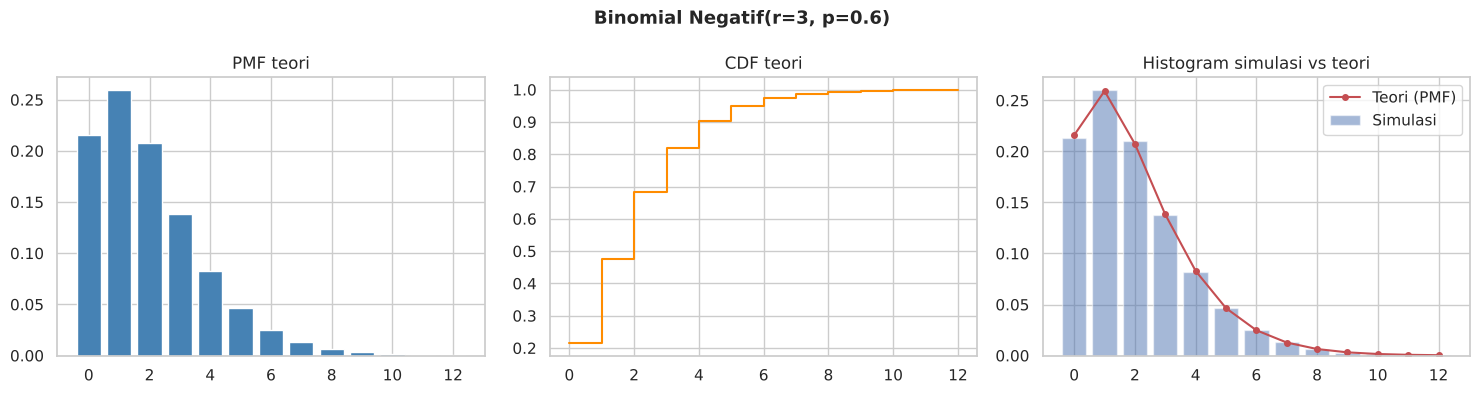

In [42]:
r, p = 3, 0.6
X = stats.nbinom(r, p)

manual_p2 = math.comb(2 + r - 1, 2) * p**r * (1 - p)**2
print(f"P(X=2)  manual={manual_p2:.6f} | scipy={X.pmf(2):.6f}")
print(f"P(X<=1) scipy={X.cdf(1):.6f}")
print(f"E[X]={X.mean():.6f} | Var(X)={X.var():.6f}")
print(f"Rata-rata total percobaan = E[X] + r = {X.mean() + r:.4f}")

np.random.seed(42)
sampel = np.random.negative_binomial(r, p, size=100_000)
ringkas_simulasi(sampel, X)

tabel_banding([("P(X=2)", 0.20736, X.pmf(2)), ("E[X]", r*(1-p)/p, X.mean()),
               ("Var(X)", r*(1-p)/p**2, X.var())])
plot_distribusi(X, sampel, np.arange(0, 13), "Binomial Negatif(r=3, p=0.6)")

**5. Perbandingan manual vs Python**

scipy.stats.nbinom memberi 0,20736; 0,4752; E = 2; Var = 3,3333 (sama persis). Simulasi numpy.negative_binomial: mean 2,00283, varians 3,315982, dekat dengan teori.

**6. Interpretasi**

Rata-rata ada 2 deploy gagal sebelum mendapat 3 sukses, jadi total sekitar 5 kali deploy. Peluang 'mulus' (gagal paling banyak 1 kali) hanya 47,5%, jadi jadwal rilis sebaiknya menyediakan waktu untuk beberapa kali deploy ulang.

**7. Kesimpulan**

Binomial Negatif adalah generalisasi Geometrik untuk sukses ke-r; perlu hati-hati dengan konvensi (jumlah gagal vs jumlah percobaan) saat memakai scipy.

## Soal D5 - Distribusi Poisson (Error Log per Jam)

**1. Soal**

Rata-rata muncul 3 error per jam di log aplikasi. Misalkan X = banyak error dalam satu jam. Hitung P(X=5), P(X>=1), P(X>6), E[X], dan Var(X).

**2. Penyelesaian manual**

- Asumsi: error muncul independen dengan laju konstan -> X ~ Poisson(lambda = 3)
- P(X=k) = e^(-lambda) lambda^k / k!
- P(X=5) = e^-3*3^5/5! = 0,049787*243/120 = 0,100819
- P(X>=1) = 1 - e^-3 = 0,950213
- E[X] = Var(X) = lambda = 3

**3. Kode Python** (hasil eksekusi di bawah sel = **4. Output**)

P(X=5)  manual=0.100819 | scipy=0.100819
P(X>=1) manual=0.950213 | scipy=0.950213
P(X>6)  scipy =0.033509
E[X] = 3.0 | Var(X) = 3.0
Mean    teori = 3.000000 | simulasi = 3.001620
Varians teori = 3.000000 | simulasi = 2.974777
Besaran   Manual   Python  Selisih
 P(X=5) 0.100819 0.100819 0.000000
P(X>=1) 0.950213 0.950213 0.000000
   E[X] 3.000000 3.000000 0.000000
 Var(X) 3.000000 3.000000 0.000000


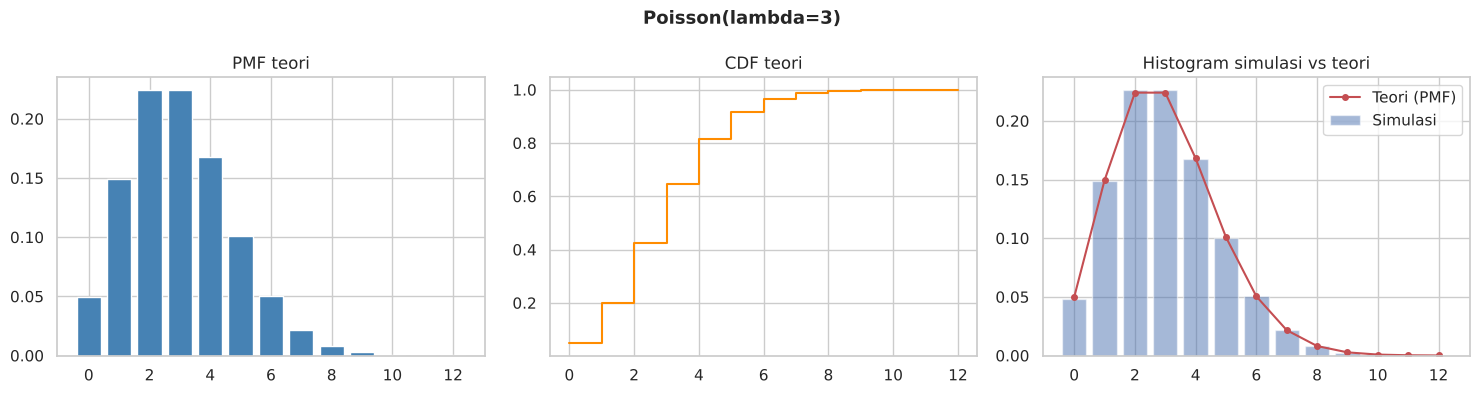

In [43]:
lam = 3
X = stats.poisson(lam)

manual_p5 = math.exp(-lam) * lam**5 / math.factorial(5)
manual_ge1 = 1 - math.exp(-lam)
print(f"P(X=5)  manual={manual_p5:.6f} | scipy={X.pmf(5):.6f}")
print(f"P(X>=1) manual={manual_ge1:.6f} | scipy={X.sf(0):.6f}")
print(f"P(X>6)  scipy ={X.sf(6):.6f}")
print("E[X] =", X.mean(), "| Var(X) =", X.var())

np.random.seed(42)
sampel = np.random.poisson(lam, size=100_000)
ringkas_simulasi(sampel, X)

tabel_banding([("P(X=5)", manual_p5, X.pmf(5)), ("P(X>=1)", manual_ge1, X.sf(0)),
               ("E[X]", 3, X.mean()), ("Var(X)", 3, X.var())])
plot_distribusi(X, sampel, np.arange(0, 13), "Poisson(lambda=3)")

**5. Perbandingan manual vs Python**

Manual dan scipy.stats.poisson identik (0,100819 dan 0,950213), P(X>6) = 0,033509. Simulasi: mean 3,00162 dan varians 2,974777; keduanya = 3 sesuai ciri Poisson (mean = varians).

**6. Interpretasi**

Hampir selalu (95%) ada minimal satu error tiap jam, jadi itu kondisi normal. Tapi kalau dalam sejam ada lebih dari 6 error, peluangnya cuma 3,4%; batas ini bisa dipakai sebagai threshold alert monitoring.

**7. Kesimpulan**

Poisson memodelkan jumlah kejadian per interval dengan E = Var = lambda, dan berguna untuk menentukan ambang alert.

## Soal D6 - Distribusi Hipergeometrik (QC Chip Tanpa Pengembalian)

**1. Soal**

Satu batch berisi 50 chip, 5 di antaranya cacat. Tim QC mengambil 10 chip tanpa pengembalian. Misalkan X = banyak chip cacat di sampel. Hitung P(X=1), P(X>=1), E[X], Var(X), dan bandingkan dengan model Binomial.

**2. Penyelesaian manual**

- X ~ Hipergeometrik(N = 50, K = 5, n = 10); P(X=k) = C(K,k)*C(N-K, n-k)/C(N,n)
- P(X=1) = C(5,1)*C(45,9)/C(50,10) = 5*886.163.135/10.272.278.170 = 0,431337
- P(X>=1) = 1 - C(45,10)/C(50,10) = 1 - 0,310563 = 0,689437
- E[X] = nK/N = 1
- Var(X) = n(K/N)(1-K/N)(N-n)/(N-1) = 10*0,1*0,9*40/49 = 0,734694

**3. Kode Python** (hasil eksekusi di bawah sel = **4. Output**)

P(X=1)  manual=0.431337 | scipy=0.431337
P(X>=1) manual=0.689437 | scipy=0.689437
E[X]=1.000000 | Var(X)=0.734694
Pembanding Binomial(10,0.1) (dengan pengembalian): Var=0.9000
Mean    teori = 1.000000 | simulasi = 1.001320
Varians teori = 0.734694 | simulasi = 0.736438
Besaran   Manual   Python  Selisih
 P(X=1) 0.431337 0.431337 0.000000
   E[X] 1.000000 1.000000 0.000000
 Var(X) 0.734694 0.734694 0.000000


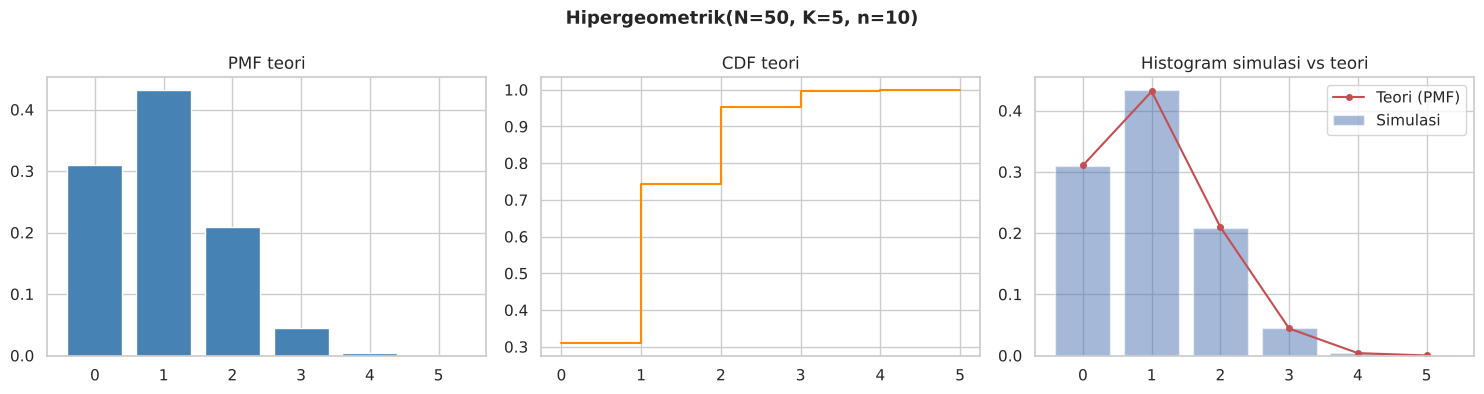

In [44]:
N_pop, K, n = 50, 5, 10
X = stats.hypergeom(M=N_pop, n=K, N=n)

manual_p1 = math.comb(5, 1) * math.comb(45, 9) / math.comb(50, 10)
manual_p0 = math.comb(45, 10) / math.comb(50, 10)
print(f"P(X=1)  manual={manual_p1:.6f} | scipy={X.pmf(1):.6f}")
print(f"P(X>=1) manual={1-manual_p0:.6f} | scipy={X.sf(0):.6f}")
print(f"E[X]={X.mean():.6f} | Var(X)={X.var():.6f}")
print(f"Pembanding Binomial(10,0.1) (dengan pengembalian): Var={stats.binom(10,0.1).var():.4f}")

np.random.seed(42)
sampel = np.random.hypergeometric(ngood=K, nbad=N_pop - K, nsample=n, size=100_000)
ringkas_simulasi(sampel, X)

var_manual = n * K / N_pop * (1 - K / N_pop) * (N_pop - n) / (N_pop - 1)
tabel_banding([("P(X=1)", manual_p1, X.pmf(1)), ("E[X]", n*K/N_pop, X.mean()), ("Var(X)", var_manual, X.var())])
plot_distribusi(X, sampel, np.arange(0, 6), "Hipergeometrik(N=50, K=5, n=10)")

**5. Perbandingan manual vs Python**

Manual (math.comb) dan scipy.stats.hypergeom memberi 0,431337; 0,689437; E = 1; Var = 0,734694 (identik). Simulasi: mean 1,00132, varians 0,736438. Model Binomial(10; 0,1) punya varians 0,9, lebih besar, karena tidak memperhitungkan faktor koreksi populasi hingga (N-n)/(N-1).

**6. Interpretasi**

Peluang QC menemukan minimal satu chip cacat sekitar 69%, jadi ada 31% kemungkinan batch cacat lolos. Kalau ingin deteksi lebih andal, ukuran sampel perlu diperbesar.

**7. Kesimpulan**

Untuk sampling tanpa pengembalian dari populasi kecil, Hipergeometrik lebih tepat daripada Binomial; varians-nya lebih kecil karena faktor koreksi populasi hingga.

## Soal D7 - Distribusi Uniform Diskrit (Load Balancer Acak)

**1. Soal**

Load balancer mengirim setiap request ke salah satu dari 8 server (ID 1-8) secara acak seragam. Misalkan X = ID server. Hitung P(X=5), P(X<=3), E[X], Var(X), dan uji apakah hasil simulasi benar-benar seragam.

**2. Penyelesaian manual**

- X ~ Uniform{1, ..., 8}; P(X=k) = 1/8
- P(X=5) = 1/8 = 0,125; P(X<=3) = 3/8 = 0,375
- E[X] = (a+b)/2 = (1+8)/2 = 4,5
- Var(X) = (n^2 - 1)/12 = (64 - 1)/12 = 5,25

**3. Kode Python** (hasil eksekusi di bawah sel = **4. Output**)

P(X=5)  = 0.125000 | P(X<=3) = 0.375000
E[X] = 4.5 | Var(X) = 5.25
Mean    teori = 4.500000 | simulasi = 4.505510
Varians teori = 5.250000 | simulasi = 5.235070
Frekuensi tiap server: [12407 12554 12300 12547 12642 12537 12588 12425]
Chi-square GoF: stat=7.0941, p-value=0.4192
Besaran   Manual   Python  Selisih
P(X<=3) 0.375000 0.375000 0.000000
   E[X] 4.500000 4.500000 0.000000
 Var(X) 5.250000 5.250000 0.000000


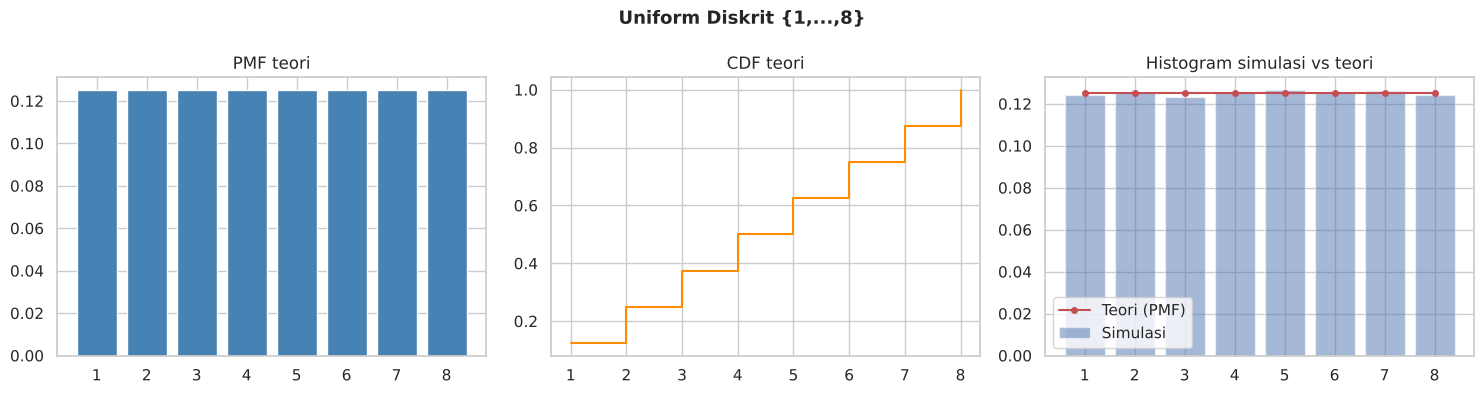

In [45]:
X = stats.randint(1, 9)

print(f"P(X=5)  = {X.pmf(5):.6f} | P(X<=3) = {X.cdf(3):.6f}")
print(f"E[X] = {X.mean()} | Var(X) = {X.var()}")

np.random.seed(42)
sampel = np.random.randint(1, 9, size=100_000)
ringkas_simulasi(sampel, X)
print("Frekuensi tiap server:", np.bincount(sampel)[1:])

chi = stats.chisquare(np.bincount(sampel)[1:])
print(f"Chi-square GoF: stat={chi.statistic:.4f}, p-value={chi.pvalue:.4f}")

tabel_banding([("P(X<=3)", 3/8, X.cdf(3)), ("E[X]", 4.5, X.mean()), ("Var(X)", 63/12, X.var())])
plot_distribusi(X, sampel, np.arange(1, 9), "Uniform Diskrit {1,...,8}")

**5. Perbandingan manual vs Python**

scipy.stats.randint(1, 9) memberi nilai identik. Simulasi 100.000 request: mean 4,50551, varians 5,23507. Frekuensi tiap server berkisar 12.300-12.642 (harapan 12.500); uji chi-square goodness-of-fit memberi p-value 0,4192 > 0,05, jadi tidak ada bukti beban tidak seragam.

**6. Interpretasi**

Setiap server menerima sekitar 12,5% trafik. Variasi kecil antarserver murni karena keacakan, bukan karena load balancer berat sebelah.

**7. Kesimpulan**

Uniform diskrit memodelkan pemilihan acak yang adil; simulasi dan uji chi-square mengonfirmasi keseragaman.

## Soal D8 - Distribusi Uniform Kontinu (Latensi Jaringan)

**1. Soal**

Latensi sebuah koneksi tersebar seragam antara 20 ms dan 50 ms. Hitung P(25 < X < 35), P(X > 45), E[X], Var(X), dan persentil ke-90.

**2. Penyelesaian manual**

- X ~ U(a = 20, b = 50); f(x) = 1/(b-a) = 1/30
- P(25 < X < 35) = (35 - 25)/30 = 1/3 = 0,333333
- P(X > 45) = (50 - 45)/30 = 1/6 = 0,166667
- E[X] = (a+b)/2 = 35; Var(X) = (b-a)^2/12 = 900/12 = 75
- Persentil 90: a + 0,9(b-a) = 20 + 27 = 47 ms

**3. Kode Python** (hasil eksekusi di bawah sel = **4. Output**)

P(25<X<35) manual=0.333333 | scipy=0.333333
P(X>45)    scipy=0.166667
E[X]=35.0 | Var(X)=75.0
Persentil 90% = 47.0 ms
Mean    teori = 35.000000 | simulasi = 34.984648
Varians teori = 75.000000 | simulasi = 74.825963
P(25<X<35) simulasi = 0.33272
   Besaran    Manual    Python  Selisih
P(25<X<35)  0.333333  0.333333 0.000000
      E[X] 35.000000 35.000000 0.000000
    Var(X) 75.000000 75.000000 0.000000


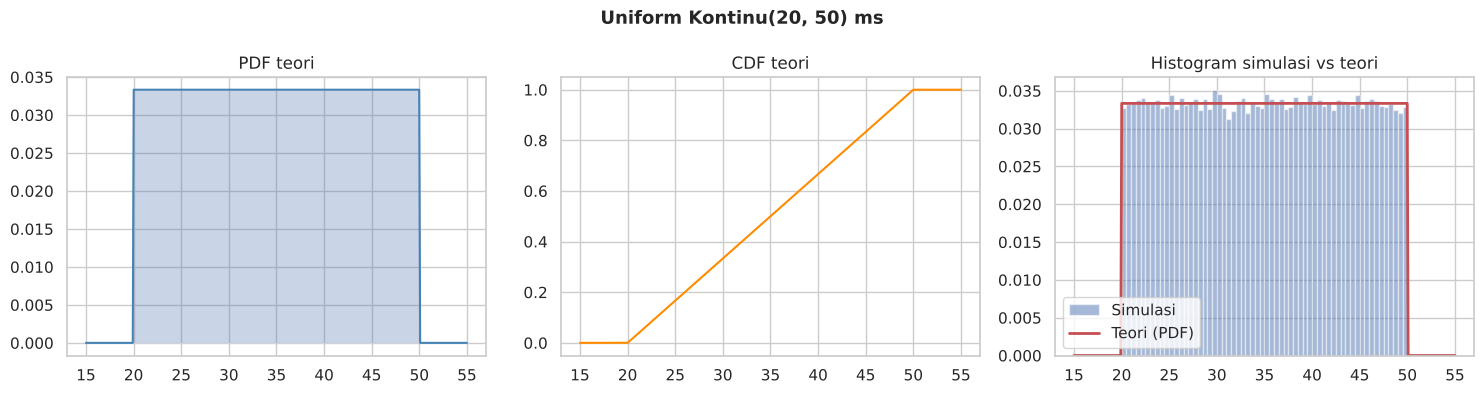

In [46]:
a, b = 20, 50
X = stats.uniform(loc=a, scale=b - a)

p_manual = (35 - 25) / (b - a)
print(f"P(25<X<35) manual={p_manual:.6f} | scipy={X.cdf(35) - X.cdf(25):.6f}")
print(f"P(X>45)    scipy={X.sf(45):.6f}")
print(f"E[X]={X.mean()} | Var(X)={X.var()}")
print(f"Persentil 90% = {X.ppf(0.9)} ms")

np.random.seed(42)
sampel = np.random.uniform(a, b, size=100_000)
ringkas_simulasi(sampel, X)
print("P(25<X<35) simulasi =", np.mean((sampel > 25) & (sampel < 35)))

tabel_banding([("P(25<X<35)", 1/3, X.cdf(35) - X.cdf(25)), ("E[X]", 35, X.mean()), ("Var(X)", 75, X.var())])
plot_distribusi(X, sampel, np.linspace(15, 55, 400), "Uniform Kontinu(20, 50) ms", diskrit=False)

**5. Perbandingan manual vs Python**

scipy.stats.uniform(loc=20, scale=30) memberi angka identik (0,333333; 0,166667; 35; 75; 47). Simulasi: mean 34,98, varians 74,83, P(25<X<35) = 0,33272, semuanya dekat dengan teori.

**6. Interpretasi**

Rata-rata latensi 35 ms dan 90% koneksi selesai di bawah 47 ms. Peluang latensi di atas 45 ms sekitar 1 dari 6 request, cukup sering untuk aplikasi real-time seperti game online.

**7. Kesimpulan**

Uniform kontinu memberi peluang sebanding panjang interval; scipy memakai parameter loc dan scale (bukan a dan b langsung).

## Soal D9 - Distribusi Normal (Response Time API, z-score, 68-95-99.7)

**1. Soal**

Response time API berdistribusi Normal dengan mu = 200 ms dan sigma = 25 ms. Hitung z-score untuk 240 ms, P(X < 250), P(180 < X < 230), persentil ke-95, dan cek aturan empiris 68-95-99,7.

**2. Penyelesaian manual**

- z = (x - mu)/sigma -> z(240) = 40/25 = 1,6
- P(X<250) = Phi((250-200)/25) = Phi(2) = 0,97725
- P(180<X<230) = Phi(1,2) - Phi(-0,8) = 0,88493 - 0,21186 = 0,67307
- Persentil 95: x = mu + 1,645sigma = 200 + 41,125 = 241,125 ms (z0,95 = 1,645 dari tabel)
- Aturan empiris: +/-1sigma = 68%, +/-2sigma = 95%, +/-3sigma = 99,7%

**3. Kode Python** (hasil eksekusi di bawah sel = **4. Output**)

z(240) = 1.6
P(X<250)     = Phi(2)              = 0.977250
P(180<X<230) = Phi(1.2)-Phi(-0.8)  = 0.673075
Persentil 95 = 241.1213 ms
+/-1sigma: teori=0.6827, simulasi=0.6816
+/-2sigma: teori=0.9545, simulasi=0.9545
+/-3sigma: teori=0.9973, simulasi=0.9974
Mean    teori = 200.000000 | simulasi = 200.024172
Varians teori = 625.000000 | simulasi = 626.126700
     Besaran     Manual     Python  Selisih
    P(X<250)   0.977250   0.977250 0.000000
P(180<X<230)   0.673070   0.673075 0.000005
Persentil 95 241.125000 241.121341 0.003659
      Var(X) 625.000000 625.000000 0.000000


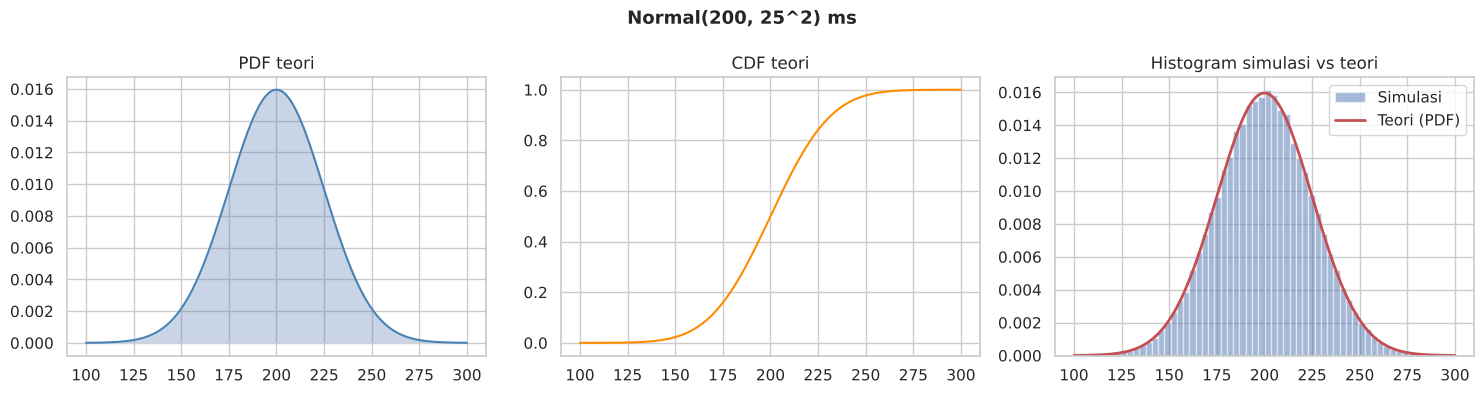

In [47]:
mu, sigma = 200, 25
X = stats.norm(mu, sigma)

z = (240 - mu) / sigma
print(f"z(240) = {z}")
print(f"P(X<250)     = Phi(2)              = {X.cdf(250):.6f}")
print(f"P(180<X<230) = Phi(1.2)-Phi(-0.8)  = {X.cdf(230) - X.cdf(180):.6f}")
print(f"Persentil 95 = {X.ppf(0.95):.4f} ms")

np.random.seed(42)
sampel = np.random.normal(mu, sigma, size=100_000)
for k in (1, 2, 3):
    teori = X.cdf(mu + k*sigma) - X.cdf(mu - k*sigma)
    sim = np.mean(np.abs(sampel - mu) < k * sigma)
    print(f"+/-{k}sigma: teori={teori:.4f}, simulasi={sim:.4f}")
ringkas_simulasi(sampel, X)

tabel_banding([("P(X<250)", 0.97725, X.cdf(250)), ("P(180<X<230)", 0.88493-0.21186, X.cdf(230)-X.cdf(180)),
               ("Persentil 95", 200+1.645*25, X.ppf(0.95)), ("Var(X)", 625, X.var())])
plot_distribusi(X, sampel, np.linspace(100, 300, 400), "Normal(200, 25^2) ms", diskrit=False)

**5. Perbandingan manual vs Python**

scipy.stats.norm memberi 0,977250 dan 0,673075 (beda 0,000005 dengan tabel karena pembulatan 5 desimal di tabel Z). Persentil 95 scipy 241,1213 vs manual 241,125; beda 0,0037 karena manual memakai z = 1,645 sedangkan nilai eksaknya 1,644854. Simulasi: +/-1sigma = 0,6816, +/-2sigma = 0,9545, +/-3sigma = 0,9974, cocok dengan 68-95-99,7.

**6. Interpretasi**

Response time 240 ms ada 1,6 simpangan baku di atas rata-rata. Sekitar 97,7% request selesai di bawah 250 ms, dan 95% request di bawah +/-241 ms; angka persentil seperti ini biasa dipakai sebagai target SLO (p95 latency).

**7. Kesimpulan**

Distribusi Normal dan z-score memudahkan menghitung peluang serta persentil; perbedaan kecil dengan tabel murni karena pembulatan.

## Soal D10 - Distribusi Eksponensial (Waktu Sampai Disk Gagal)

**1. Soal**

Waktu sampai sebuah hard disk gagal berdistribusi Eksponensial dengan rata-rata 1000 jam. Hitung P(X > 500), P(X <= 2000), median, E[X], Var(X), dan tunjukkan sifat memoryless.

**2. Penyelesaian manual**

- X ~ Exp(lambda = 1/1000); F(x) = 1 - e^(-lambda*x)
- P(X>500) = e^(-0,5) = 0,606531
- P(X<=2000) = 1 - e^(-2) = 0,864665
- Median = ln2/lambda = 1000*ln2 = 693,1472 jam
- E[X] = 1/lambda = 1000; Var(X) = 1/lambda^2 = 1.000.000
- Memoryless: P(X>1500 | X>1000) = P(X>500) = 0,606531

**3. Kode Python** (hasil eksekusi di bawah sel = **4. Output**)

P(X>500)   manual=0.606531 | scipy=0.606531
P(X<=2000) manual=0.864665 | scipy=0.864665
Median = 693.1472 jam (manual 1000*ln2 = 693.1472)
E[X]=1000.0 | Var(X)=1000000.0
Mean    teori = 1000.000000 | simulasi = 995.970159
Varians teori = 1000000.000000 | simulasi = 985987.528924
Memoryless simulasi: P(X>1500|X>1000)=0.6052 vs P(X>500)=0.6064
 Besaran         Manual         Python  Selisih
P(X>500)       0.606531       0.606531 0.000000
    E[X]    1000.000000    1000.000000 0.000000
  Var(X) 1000000.000000 1000000.000000 0.000000


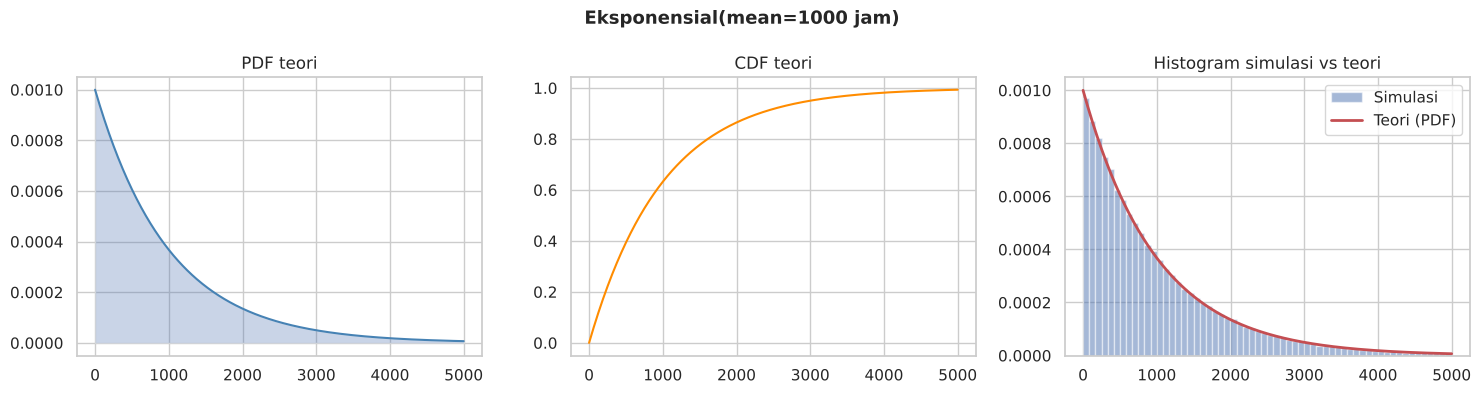

In [48]:
mean = 1000
X = stats.expon(scale=mean)

print(f"P(X>500)   manual={math.exp(-0.5):.6f} | scipy={X.sf(500):.6f}")
print(f"P(X<=2000) manual={1-math.exp(-2):.6f} | scipy={X.cdf(2000):.6f}")
print(f"Median = {X.median():.4f} jam (manual 1000*ln2 = {1000*math.log(2):.4f})")
print(f"E[X]={X.mean()} | Var(X)={X.var()}")

np.random.seed(42)
sampel = np.random.exponential(mean, size=100_000)
ringkas_simulasi(sampel, X)
print(f"Memoryless simulasi: P(X>1500|X>1000)={np.mean(sampel[sampel>1000] > 1500):.4f} vs P(X>500)={np.mean(sampel>500):.4f}")

tabel_banding([("P(X>500)", math.exp(-0.5), X.sf(500)), ("E[X]", 1000, X.mean()), ("Var(X)", 1e6, X.var())])
plot_distribusi(X, sampel, np.linspace(0, 5000, 400), "Eksponensial(mean=1000 jam)", diskrit=False)

**5. Perbandingan manual vs Python**

scipy.stats.expon(scale=1000) memberi angka identik. Simulasi: mean 995,97 dan varians 985.987,5 (selisih ~1,4% dari teori, wajar karena varians distribusi berekor panjang lebih lambat konvergen). Memoryless di simulasi: 0,6052 vs 0,6064.

**6. Interpretasi**

Setengah disk sudah gagal sebelum 693 jam, lebih cepat dari rata-ratanya (1000 jam), karena distribusinya miring ke kanan. Sifat memoryless berarti disk yang sudah jalan 1000 jam peluang bertahan 500 jam lagi sama dengan disk baru, model ini cocok untuk kegagalan acak, bukan aus.

**7. Kesimpulan**

Eksponensial memodelkan waktu tunggu kejadian acak dengan E = 1/lambda dan bersifat memoryless; scipy dan simulasi konsisten.

## Soal D11 - Distribusi Gamma (Waktu Tunggu 3 Request)

**1. Soal**

Request datang ke server sebagai proses Poisson dengan laju 2 request/detik. Misalkan T = waktu sampai request ke-3 datang. Hitung P(T <= 1 detik), E[T], dan Var(T).

**2. Penyelesaian manual**

- T adalah jumlah 3 waktu antar-kedatangan Exp(lambda=2) -> T ~ Gamma(k = 3, theta = 1/lambda = 0,5)
- Hubungan dengan Poisson: T <= 1 setara dengan minimal 3 kedatangan dalam 1 detik, N(1) ~ Poisson(2)
- P(T<=1) = 1 - e^-2(1 + 2 + 2^2/2) = 1 - 5e^-2 = 0,323324
- E[T] = ktheta = 1,5 detik; Var(T) = ktheta^2 = 0,75

**3. Kode Python** (hasil eksekusi di bawah sel = **4. Output**)

P(T<=1) manual=0.323324 | scipy gamma=0.323324 | via Poisson=0.323324
E[T]=1.5 | Var(T)=0.75
Mean    teori = 1.500000 | simulasi = 1.501698
Varians teori = 0.750000 | simulasi = 0.748428
P(T<=1) simulasi = 0.32181
Besaran   Manual   Python  Selisih
P(T<=1) 0.323324 0.323324 0.000000
   E[T] 1.500000 1.500000 0.000000
 Var(T) 0.750000 0.750000 0.000000


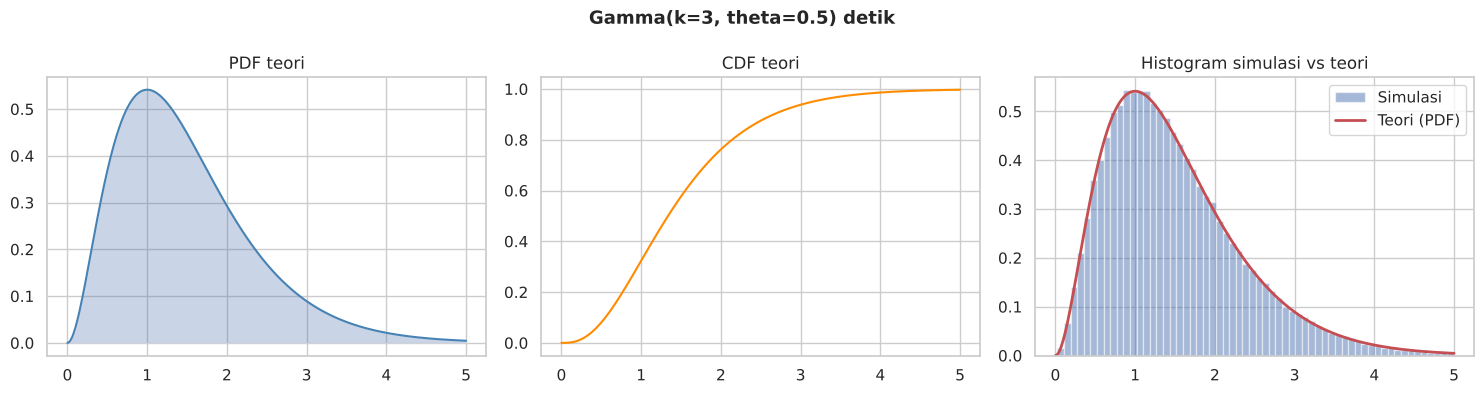

In [49]:
k, lam = 3, 2
X = stats.gamma(a=k, scale=1 / lam)

manual = 1 - math.exp(-2) * (1 + 2 + 2**2 / 2)
print(f"P(T<=1) manual={manual:.6f} | scipy gamma={X.cdf(1):.6f} | via Poisson={stats.poisson(2).sf(2):.6f}")
print(f"E[T]={X.mean()} | Var(T)={X.var()}")

np.random.seed(42)
sampel = np.random.exponential(1 / lam, size=(100_000, k)).sum(axis=1)
ringkas_simulasi(sampel, X)
print("P(T<=1) simulasi =", np.mean(sampel <= 1))

tabel_banding([("P(T<=1)", manual, X.cdf(1)), ("E[T]", k/lam, X.mean()), ("Var(T)", k/lam**2, X.var())])
plot_distribusi(X, sampel, np.linspace(0, 5, 400), "Gamma(k=3, theta=0.5) detik", diskrit=False)

**5. Perbandingan manual vs Python**

Tiga cara memberi hasil sama: manual 0,323324, scipy.stats.gamma 0,323324, dan poisson.sf(2) 0,323324. Simulasi (jumlah 3 eksponensial): mean 1,5017, varians 0,7484, P(T<=1) = 0,32181.

**6. Interpretasi**

Rata-rata butuh 1,5 detik sampai 3 request terkumpul, dan hanya sekitar 32% kemungkinan 3 request datang dalam 1 detik pertama. Ini berguna misalnya untuk menentukan kapan batch processing dijalankan.

**7. Kesimpulan**

Gamma adalah jumlah beberapa eksponensial dan berkaitan erat dengan Poisson; hubungan itu terbukti secara numerik.

## Soal D12 - Distribusi Beta (Estimasi Tingkat Keberhasilan Fitur)

**1. Soal**

Sebuah fitur baru diuji ke 60 pengguna dan 45 berhasil menyelesaikan tugas. Dengan prior Beta(1,1) (uniform), tentukan distribusi posterior tingkat keberhasilan p, E[p], Var(p), P(p > 0,7), dan interval kredibel 95%. Bandingkan dengan CI Wilson dari statsmodels.

**2. Penyelesaian manual**

- Prior Beta(alpha0=1, beta0=1) + data Binomial (45 sukses, 15 gagal) -> posterior Beta(alpha = 1+45, beta = 1+15) = Beta(46, 16) (sifat konjugat)
- E[p] = alpha/(alpha+beta) = 46/62 = 0,741935
- Var(p) = alphabeta/((alpha+beta)^2(alpha+beta+1)) = 736/(3844*63) = 736/242.172 = 0,003039
- P(p>0,7) dan interval kredibel butuh integral fungsi beta tak lengkap, jadi dihitung numerik dengan scipy

**3. Kode Python** (hasil eksekusi di bawah sel = **4. Output**)

Posterior Beta(46,16)
E[p]  manual=0.741935 | scipy=0.741935
Var   manual=0.003039 | scipy=0.003039
P(p > 0.7)  = 0.780719
Credible interval 95% Bayes   : (0.6271, 0.8420)
CI 95% Wilson (statsmodels)   : (0.6277, 0.8422)
Mean    teori = 0.741935 | simulasi = 0.741848
Varians teori = 0.003039 | simulasi = 0.003032
P(p>0.7) simulasi = 0.78038
              Besaran   Manual   Python  Selisih
                 E[p] 0.741935 0.741935 0.000000
               Var(p) 0.003039 0.003039 0.000000
P(p>0.7) sim vs scipy 0.780719 0.780380 0.000339


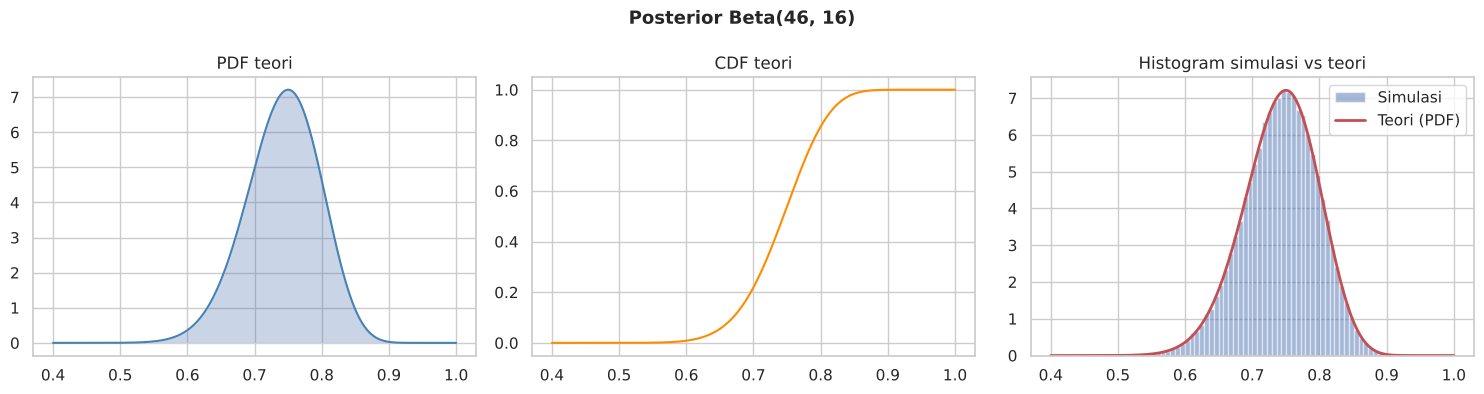

In [50]:
sukses, n = 45, 60
a0, b0 = 1, 1
a, b = a0 + sukses, b0 + n - sukses
X = stats.beta(a, b)

E_manual = a / (a + b)
V_manual = a * b / ((a + b)**2 * (a + b + 1))
print(f"Posterior Beta({a},{b})")
print(f"E[p]  manual={E_manual:.6f} | scipy={X.mean():.6f}")
print(f"Var   manual={V_manual:.6f} | scipy={X.var():.6f}")
print(f"P(p > 0.7)  = {X.sf(0.7):.6f}")
lo, hi = X.interval(0.95)
print(f"Credible interval 95% Bayes   : ({lo:.4f}, {hi:.4f})")
print("CI 95% Wilson (statsmodels)   : ({:.4f}, {:.4f})".format(*proportion_confint(sukses, n, method="wilson")))

np.random.seed(42)
sampel = np.random.beta(a, b, size=100_000)
ringkas_simulasi(sampel, X)
print("P(p>0.7) simulasi =", np.mean(sampel > 0.7))

tabel_banding([("E[p]", 46/62, X.mean()), ("Var(p)", V_manual, X.var()), ("P(p>0.7) sim vs scipy", X.sf(0.7), np.mean(sampel > 0.7))])
plot_distribusi(X, sampel, np.linspace(0.4, 1, 400), "Posterior Beta(46, 16)", diskrit=False)

**5. Perbandingan manual vs Python**

E dan Var manual sama persis dengan scipy.stats.beta. P(p>0,7) = 0,780719 (scipy) vs 0,78038 (simulasi). Interval kredibel Bayes (0,6271; 0,8420) hampir sama dengan CI Wilson frekuentis (0,6277; 0,8422) dari statsmodels.

**6. Interpretasi**

Tingkat keberhasilan fitur diperkirakan sekitar 74%, dengan keyakinan 95% berada di rentang 63-84%. Peluang tingkat keberhasilan sebenarnya di atas 70% sekitar 78%, jadi fitur ini cukup menjanjikan tapi masih perlu data tambahan untuk kesimpulan yang lebih pasti.

**7. Kesimpulan**

Distribusi Beta cocok untuk memodelkan ketidakpastian sebuah proporsi; pendekatan Bayes dan frekuentis memberi interval yang mirip pada data ini.

## Soal D13 - Pendekatan Poisson & Normal terhadap Binomial

**1. Soal**

(a) Dari 1000 paket, peluang tiap paket hilang 0,003. Hitung P(X <= 5) dengan Binomial eksak dan pendekatan Poisson. (b) Dari 500 request, peluang cache miss 0,2. Hitung P(X <= 110) dengan Binomial eksak dan pendekatan Normal (dengan dan tanpa koreksi kontinuitas).

**2. Penyelesaian manual**

- (a) n besar, p kecil -> Poisson(lambda = np = 3). P(X<=5) = e^-3 jumlah untuk k=0 sampai 5 dari 3^k/k! = 0,916082
- (b) np = 100 >= 5 dan n(1-p) = 400 >= 5 -> Normal(mu = 100, sigma = akar(80) = 8,944)
- Tanpa koreksi: z = (110 - 100)/8,944 = 1,118 -> Phi = 0,8682
- Dengan koreksi kontinuitas: z = (110,5 - 100)/8,944 = 1,174 -> Phi = 0,8798

**3. Kode Python** (hasil eksekusi di bawah sel = **4. Output**)

P(X<=5) Binomial eksak = 0.916385 | Poisson = 0.916082

mu=100.0, sigma=8.9443
P(X<=110) Binomial eksak       = 0.879025
Normal tanpa koreksi           = 0.868224
Normal dengan koreksi (110.5)  = 0.879790
Simulasi P(X<=110) = 0.878640 | mean=100.0392, var=79.5662


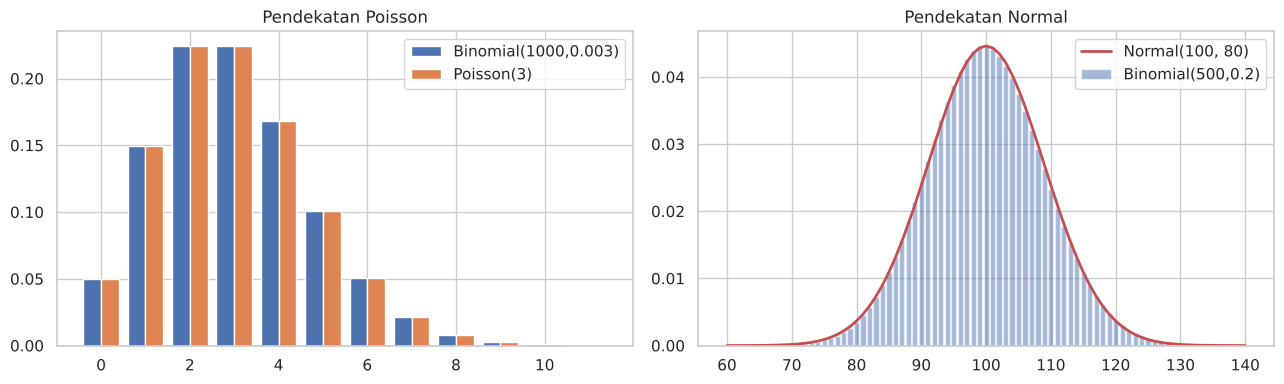

                         Besaran   Manual   Python  Selisih
             Poisson vs Binomial 0.916385 0.916082 0.000303
      Normal+koreksi vs Binomial 0.879025 0.879790 0.000765
Normal tanpa koreksi vs Binomial 0.879025 0.868224 0.010801


In [51]:
B1, P1 = stats.binom(1000, 0.003), stats.poisson(3)
print(f"P(X<=5) Binomial eksak = {B1.cdf(5):.6f} | Poisson = {P1.cdf(5):.6f}")

n, p = 500, 0.2
mu, sd = n * p, math.sqrt(n * p * (1 - p))
B2 = stats.binom(n, p)
tanpa_kk = stats.norm(mu, sd).cdf(110)
dengan_kk = stats.norm(mu, sd).cdf(110.5)
print(f"\nmu={mu}, sigma={sd:.4f}")
print(f"P(X<=110) Binomial eksak       = {B2.cdf(110):.6f}")
print(f"Normal tanpa koreksi           = {tanpa_kk:.6f}")
print(f"Normal dengan koreksi (110.5)  = {dengan_kk:.6f}")

np.random.seed(42)
s = np.random.binomial(n, p, 100_000)
print(f"Simulasi P(X<=110) = {np.mean(s <= 110):.6f} | mean={s.mean():.4f}, var={s.var():.4f}")

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
k = np.arange(0, 12)
ax[0].bar(k - 0.2, B1.pmf(k), 0.4, label="Binomial(1000,0.003)")
ax[0].bar(k + 0.2, P1.pmf(k), 0.4, label="Poisson(3)"); ax[0].legend(); ax[0].set_title("Pendekatan Poisson")
k2 = np.arange(60, 141)
ax[1].bar(k2, B2.pmf(k2), alpha=0.5, label="Binomial(500,0.2)")
ax[1].plot(k2, stats.norm(mu, sd).pdf(k2), "r-", lw=2, label="Normal(100, 80)")
ax[1].legend(); ax[1].set_title("Pendekatan Normal")
plt.tight_layout(); plt.show()

tabel_banding([("Poisson vs Binomial", B1.cdf(5), P1.cdf(5)),
               ("Normal+koreksi vs Binomial", B2.cdf(110), dengan_kk),
               ("Normal tanpa koreksi vs Binomial", B2.cdf(110), tanpa_kk)])

**5. Perbandingan manual vs Python**

Binomial eksak (a) = 0,916385 vs Poisson 0,916082 (selisih 0,0003). Binomial eksak (b) = 0,879025; Normal dengan koreksi 0,879790 (selisih 0,0008) sedangkan tanpa koreksi 0,868224 (selisih 0,0108). Simulasi: 0,87864.

**6. Interpretasi**

Kedua pendekatan bekerja sangat baik jika syaratnya terpenuhi. Koreksi kontinuitas penting: tanpa itu galatnya 14 kali lebih besar, karena Binomial diskrit sedangkan Normal kontinu.

**7. Kesimpulan**

Poisson cocok mendekati Binomial dengan n besar dan p kecil, sedangkan Normal (plus koreksi kontinuitas) cocok saat np dan n(1-p) cukup besar.

## Soal D14 - Central Limit Theorem (Rata-rata Ukuran File)

**1. Soal**

Ukuran file yang diunggah ke server berdistribusi Eksponensial dengan rata-rata 2 MB (sangat miring). Tunjukkan bahwa distribusi rata-rata sampel untuk n = 1, 5, 30 makin mendekati Normal, dan hitung P(rata-rata 50 file > 2,5 MB) dengan CLT, nilai eksak, dan simulasi.

**2. Penyelesaian manual**

- Populasi: mu = 2, sigma = 2. Menurut CLT: Xbarn = N(mu, sigma/akar n)
- SE: n=1 -> 2; n=5 -> 0,8944; n=30 -> 0,3651; n=50 -> 0,2828
- P(Xbar50 > 2,5) = 1 - Phi((2,5 - 2)/0,2828) = 1 - Phi(1,768) = 0,03855
- Nilai eksak: jumlah 50 eksponensial ~ Gamma(50, theta=2), sehingga P(Xbar > 2,5) = P(jumlah X > 125)

**3. Kode Python** (hasil eksekusi di bawah sel = **4. Output**)

n= 1: mean xbar=1.9919 (teori 2) | sd xbar=1.9859 (teori 2.0000) | skewness=1.9921
n= 5: mean xbar=2.0018 (teori 2) | sd xbar=0.8972 (teori 0.8944) | skewness=0.9134


n=30: mean xbar=2.0000 (teori 2) | sd xbar=0.3655 (teori 0.3651) | skewness=0.3597


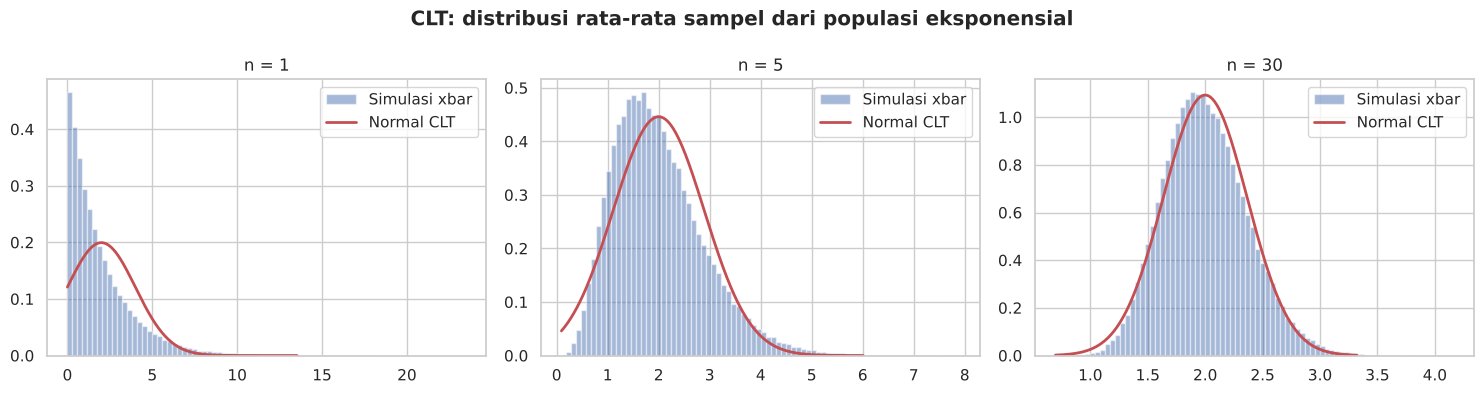


P(xbar_50 > 2.5): CLT=0.038550 | eksak Gamma=0.045990 | simulasi=0.045870
          Besaran   Manual   Python  Selisih
     CLT vs eksak 0.045990 0.038550 0.007440
Simulasi vs eksak 0.045990 0.045870 0.000120


In [52]:
mu, sigma = 2, 2
np.random.seed(42)
R = 100_000

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for i, n in enumerate([1, 5, 30]):
    xbar = np.random.exponential(mu, size=(R, n)).mean(axis=1)
    se = sigma / np.sqrt(n)
    x = np.linspace(xbar.min(), np.percentile(xbar, 99.9), 300)
    ax[i].hist(xbar, bins=80, density=True, alpha=0.5, label="Simulasi xbar")
    ax[i].plot(x, stats.norm(mu, se).pdf(x), "r-", lw=2, label="Normal CLT")
    ax[i].set_title(f"n = {n}"); ax[i].legend()
    print(f"n={n:>2}: mean xbar={xbar.mean():.4f} (teori 2) | sd xbar={xbar.std():.4f} (teori {se:.4f}) | skewness={stats.skew(xbar):.4f}")
fig.suptitle("CLT: distribusi rata-rata sampel dari populasi eksponensial", fontweight="bold")
plt.tight_layout(); plt.show()

n = 50
clt = stats.norm(mu, sigma / np.sqrt(n)).sf(2.5)
eksak = stats.gamma(a=n, scale=mu).sf(2.5 * n)
sim = np.mean(np.random.exponential(mu, size=(R, n)).mean(axis=1) > 2.5)
print(f"\nP(xbar_50 > 2.5): CLT={clt:.6f} | eksak Gamma={eksak:.6f} | simulasi={sim:.6f}")

tabel_banding([("CLT vs eksak", eksak, clt), ("Simulasi vs eksak", eksak, sim)])

**5. Perbandingan manual vs Python**

Simulasi mean Xbar = 2 untuk semua n, dan SD Xbar = 1,9859; 0,8972; 0,3655 hampir sama dengan sigma/akar n. Skewness turun dari 1,99 -> 0,91 -> 0,36, artinya bentuk distribusi makin simetris. Untuk P(Xbar50 > 2,5): CLT 0,03855, eksak Gamma 0,04599, simulasi 0,04587. CLT meleset 0,0074 karena populasi asal sangat miring sehingga n = 50 belum sepenuhnya normal di ekor.

**6. Interpretasi**

Walaupun ukuran file individual sangat tidak simetris, rata-rata dari banyak file berperilaku hampir normal, inilah dasar kenapa kita bisa memakai z-test untuk rata-rata. Tapi untuk peluang di ekor, CLT bisa underestimate kalau populasinya sangat miring.

**7. Kesimpulan**

CLT terbukti: rata-rata sampel mendekati Normal dengan SE = sigma/akar n; namun untuk populasi miring, n besar diperlukan agar peluang ekor akurat.

## Soal D15 - Gabungan: Sistem Antrian Server M/M/1 (Poisson + Eksponensial)

**1. Soal**

Request datang ke sebuah server tunggal mengikuti proses Poisson dengan laju lambda = 8 request/detik, dan waktu layanan berdistribusi Eksponensial dengan laju mu = 10 request/detik (model M/M/1). Hitung utilisasi, rata-rata jumlah request di sistem (L), waktu rata-rata di sistem (W), waktu tunggu di antrian (Wq), P(sistem kosong), P(>=5 request di sistem), dan P(lebih dari 12 kedatangan dalam 1 detik). Verifikasi dengan simulasi 100.000 request.

**2. Penyelesaian manual**

- Asumsi: kedatangan Poisson, layanan eksponensial, 1 server, antrian FIFO tak terbatas, rho < 1 (stabil)
- rho = lambda/mu = 0,8
- L = rho/(1-rho) = 4; Lq = rho^2/(1-rho) = 3,2
- W = 1/(mu-lambda) = 0,5 detik; Wq = rho/(mu-lambda) = 0,4 detik (cek Little: L = lambda*W = 8*0,5 = 4 (sesuai))
- P(sistem kosong) = 1 - rho = 0,2; P(N >= 5) = rho^5 = 0,32768
- Kedatangan per detik ~ Poisson(8): P(N>12) = 1 - jumlah untuk k=0 sampai 12 dari e^-88^k/k! = 0,063797
- Waktu di sistem W ~ Exp(mu-lambda = 2)

**3. Kode Python** (hasil eksekusi di bawah sel = **4. Output**)

Teori M/M/1: {'rho': 0.8, 'L': 4.0, 'W': 0.5, 'Wq': 0.4, 'Lq': 3.2}
P(sistem kosong) = 0.2000 | P(>=5 request di sistem) = 0.327680
P(kedatangan dalam 1 detik > 12) = 0.063797

Simulasi: W=0.5043 s (teori 0.5) | Wq=0.4038 s (teori 0.4)
Proporsi request langsung dilayani (Wq=0) = 0.1927 (teori 0.2000)
Kedatangan per detik: mean=8.0324, var=7.9512 (Poisson: keduanya 8)


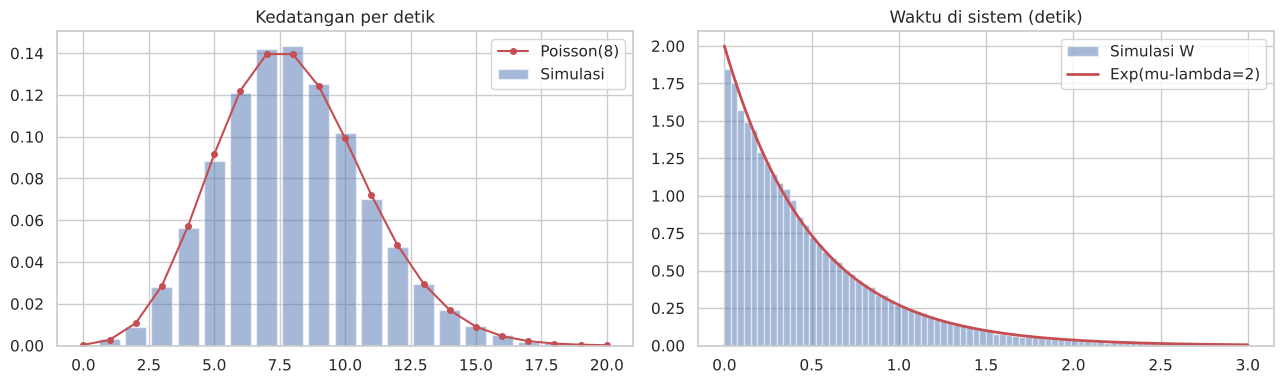

              Besaran   Manual   Python  Selisih
                    W 0.500000 0.504277 0.004277
                   Wq 0.400000 0.403818 0.003818
              P(Wq=0) 0.200000 0.192670 0.007330
Mean kedatangan/detik 8.000000 8.032372 0.032372


In [53]:
lam, mu = 8, 10
rho = lam / mu
teori = {"rho": rho, "L": rho / (1 - rho), "W": 1 / (mu - lam), "Wq": rho / (mu - lam), "Lq": rho**2 / (1 - rho)}
print("Teori M/M/1:", {k: round(v, 4) for k, v in teori.items()})
print(f"P(sistem kosong) = {1 - rho:.4f} | P(>=5 request di sistem) = {rho**5:.6f}")
print(f"P(kedatangan dalam 1 detik > 12) = {stats.poisson(lam).sf(12):.6f}")

np.random.seed(42)
N = 100_000
antar = np.random.exponential(1 / lam, N)
layan = np.random.exponential(1 / mu, N)
Wq = np.zeros(N)
for i in range(1, N):
    Wq[i] = max(0.0, Wq[i - 1] + layan[i - 1] - antar[i])
W = Wq + layan
print(f"\nSimulasi: W={W.mean():.4f} s (teori 0.5) | Wq={Wq.mean():.4f} s (teori 0.4)")
print(f"Proporsi request langsung dilayani (Wq=0) = {np.mean(Wq == 0):.4f} (teori {1-rho:.4f})")

t = np.cumsum(antar)
per_detik = np.bincount(t.astype(int))[:-1]
print(f"Kedatangan per detik: mean={per_detik.mean():.4f}, var={per_detik.var():.4f} (Poisson: keduanya 8)")

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
k = np.arange(0, 21)
nilai, frek = np.unique(per_detik, return_counts=True)
ax[0].bar(nilai, frek / len(per_detik), alpha=0.5, label="Simulasi")
ax[0].plot(k, stats.poisson(lam).pmf(k), "ro-", ms=4, label="Poisson(8)")
ax[0].set_xlim(-1, 21); ax[0].set_title("Kedatangan per detik"); ax[0].legend()
x = np.linspace(0, 3, 300)
ax[1].hist(W[W < 3], bins=80, density=True, alpha=0.5, label="Simulasi W")
ax[1].plot(x, stats.expon(scale=1 / (mu - lam)).pdf(x), "r-", lw=2, label="Exp(mu-lambda=2)")
ax[1].set_title("Waktu di sistem (detik)"); ax[1].legend()
plt.tight_layout(); plt.show()

tabel_banding([("W", teori["W"], W.mean()), ("Wq", teori["Wq"], Wq.mean()),
               ("P(Wq=0)", 1 - rho, np.mean(Wq == 0)), ("Mean kedatangan/detik", 8, per_detik.mean())])

**5. Perbandingan manual vs Python**

Simulasi (rekursi Lindley) memberi W = 0,5043 s dan Wq = 0,4038 s (teori 0,5 dan 0,4); proporsi request yang langsung dilayani 0,1927 (teori 0,2). Kedatangan per detik: mean 8,03 dan varians 7,95, keduanya = 8 sesuai Poisson. Histogram W juga menempel pada kurva Exp(2). Selisih kecil muncul karena simulasi dimulai dari sistem kosong dan antrian punya autokorelasi tinggi pada rho = 0,8.

**6. Interpretasi**

Server sibuk 80% waktu, dan meskipun layanan rata-rata cuma 0,1 detik, request menghabiskan 0,5 detik di sistem karena 0,4 detik dipakai untuk mengantre. Sepertiga waktu ada 5 request atau lebih yang menumpuk, dan sekitar 6,4% detik akan menerima lonjakan lebih dari 12 request. Kalau trafik naik mendekati 10 req/s, waktu tunggu akan meledak, jadi perlu scaling sebelum itu.

**7. Kesimpulan**

Model M/M/1 menggabungkan Poisson (kedatangan) dan Eksponensial (layanan); rumus teori dan simulasi konsisten serta bisa dipakai untuk perencanaan kapasitas server.

## Soal D16 - Distribusi Zipf (Popularitas Konten untuk Cache)

**1. Soal**

Ada 100 konten di sebuah CDN. Peluang konten dengan ranking k diminta mengikuti hukum Zipf dengan s = 1: P(X=k) = (1/k)/H100. Hitung peluang konten ranking 1 diminta, peluang permintaan jatuh pada 10 konten teratas (hit ratio cache top-10), E[X], dan Var(X).

**2. Penyelesaian manual**

- H100 = jumlah untuk k=1 sampai 100 dari 1/k = 5,187378
- P(X=1) = 1/5,187378 = 0,192776
- P(X<=10) = H10/H100 = 2,928968/5,187378 = 0,564634
- E[X] = jumlah k*(1/k)/H100 = 100/H100 = 19,2776

**3. Kode Python** (hasil eksekusi di bawah sel = **4. Output**)

H_100 = 5.187378
P(X=1)   manual = 0.192776 | scipy = 0.192776
P(X<=10) manual = 0.564634 | scipy = 0.564634
E[X] = 19.2776 | Var(X) = 601.8925


Mean    teori = 19.277564 | simulasi = 19.185040
Varians teori = 601.892503 | simulasi = 595.339340
Hit ratio cache top-10 (simulasi) = 0.5650
      Besaran    Manual    Python  Selisih
       P(X=1)  0.192776  0.192776 0.000000
     P(X<=10)  0.564634  0.564634 0.000000
Mean simulasi 19.277564 19.185040 0.092524


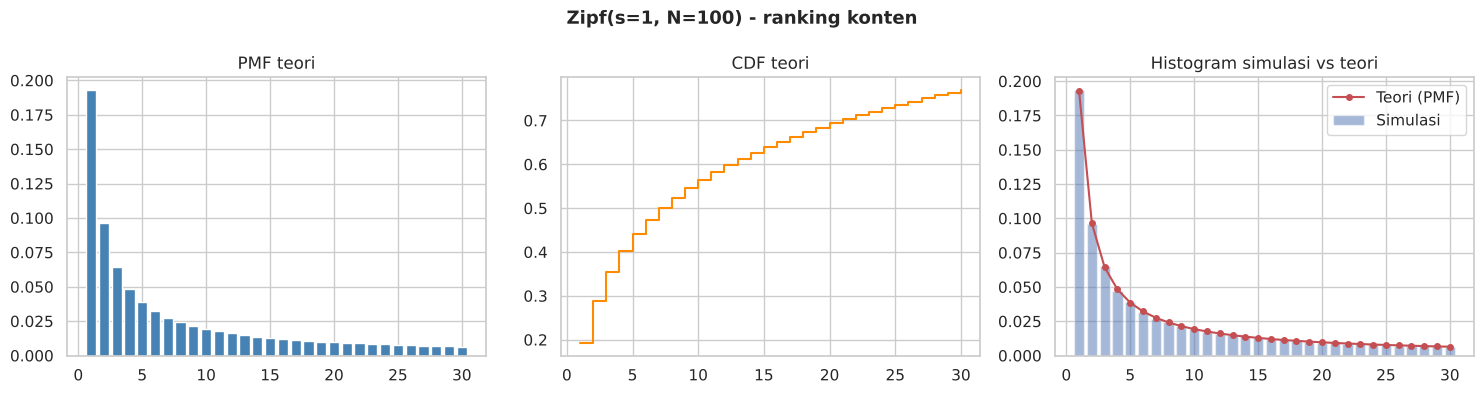

In [54]:
N_konten, s = 100, 1.0
X = stats.zipfian(s, N_konten)

H = sum(1 / k**s for k in range(1, N_konten + 1))
print(f"H_100 = {H:.6f}")
print(f"P(X=1)   manual = {1/H:.6f} | scipy = {X.pmf(1):.6f}")
print(f"P(X<=10) manual = {sum(1/k for k in range(1, 11))/H:.6f} | scipy = {X.cdf(10):.6f}")
print(f"E[X] = {X.mean():.4f} | Var(X) = {X.var():.4f}")

np.random.seed(42)
sampel = X.rvs(size=100_000)
ringkas_simulasi(sampel, X)
print(f"Hit ratio cache top-10 (simulasi) = {np.mean(sampel <= 10):.4f}")

tabel_banding([("P(X=1)", 1/5.187378, X.pmf(1)), ("P(X<=10)", 2.928968/5.187378, X.cdf(10)),
               ("Mean simulasi", X.mean(), sampel.mean())])
plot_distribusi(X, sampel, np.arange(1, 31), "Zipf(s=1, N=100) - ranking konten")

**5. Perbandingan manual vs Python**

scipy.stats.zipfian memberi 0,192776; 0,564634; E = 19,2776 (sama dengan manual) dan Var = 601,89. Simulasi 100.000 permintaan memberi mean 19,185 dan hit ratio top-10 = 0,565.

**6. Interpretasi**

Satu konten paling populer saja sudah menyerap hampir 19% permintaan, dan dengan meng-cache 10% konten (10 dari 100) sekitar 56% permintaan bisa dilayani dari cache. Inilah alasan kenapa caching sangat efektif untuk trafik web.

**7. Kesimpulan**

Distribusi Zipf menggambarkan popularitas yang timpang; sedikit item teratas menyumbang sebagian besar permintaan.

## Soal D17 - Distribusi Normal Multivariat (CPU & RAM Usage)

**1. Soal**

Pemakaian CPU dan RAM (%) sebuah server berdistribusi normal bivariat dengan mu = (50, 60), sigma = (10, 8), dan korelasi rho = 0,6. Hitung P(CPU > 65 dan RAM > 70), bandingkan dengan jika dianggap independen, dan tentukan distribusi RAM jika diketahui CPU = 70%.

**2. Penyelesaian manual**

- Marginal: P(CPU>65) = 1 - Phi(1,5) = 0,066807; P(RAM>70) = 1 - Phi(1,25) = 0,105650
- Jika independen: 0,066807 x 0,105650 = 0,007058
- Dengan korelasi: P = 1 - F_CPU(65) - F_RAM(70) + F(65, 70), F gabungan dihitung numerik
- Bersyarat: RAM | CPU=70 ~ N(mu2 + rho(sigma2/sigma1)(70 - mu1); sigma2^2(1 - rho^2)) = N(60 + 0,6*0,8*20; 64*0,64) = N(69,6; 6,4^2)
- P(RAM>70 | CPU=70) = 1 - Phi((70 - 69,6)/6,4) = 1 - Phi(0,0625) = 0,4751

**3. Kode Python** (hasil eksekusi di bawah sel = **4. Output**)

P(CPU>65) = 0.066807 | P(RAM>70) = 0.105650
Jika independen P = 0.007058 | dengan korelasi 0.6 P = 0.030495
RAM | CPU=70 ~ Normal(69.60, 6.40^2) -> P(RAM>70 | CPU=70) = 0.475082
Simulasi: mean=[49.9577 59.9453], korelasi=0.6019
Simulasi P(CPU>65, RAM>70) = 0.030430


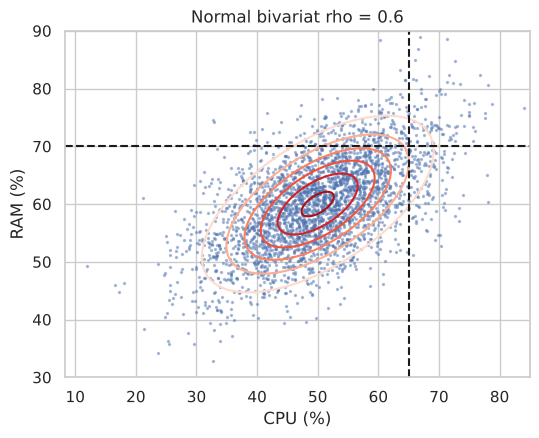

         Besaran    Manual    Python  Selisih
P(CPU>65,RAM>70)  0.030495  0.030430 0.000065
        Korelasi  0.600000  0.601911 0.001911
   E[RAM|CPU=70] 69.600000 69.600000 0.000000


In [55]:
mu = np.array([50, 60])
sd = np.array([10, 8]); rho = 0.6
cov = np.array([[sd[0]**2, rho*sd[0]*sd[1]], [rho*sd[0]*sd[1], sd[1]**2]])
mvn = stats.multivariate_normal(mu, cov)

p_cpu, p_ram = stats.norm(50, 10).sf(65), stats.norm(60, 8).sf(70)
p_joint = 1 - stats.norm(50, 10).cdf(65) - stats.norm(60, 8).cdf(70) + mvn.cdf([65, 70])
print(f"P(CPU>65) = {p_cpu:.6f} | P(RAM>70) = {p_ram:.6f}")
print(f"Jika independen P = {p_cpu*p_ram:.6f} | dengan korelasi 0.6 P = {p_joint:.6f}")

m_c = mu[1] + rho * sd[1] / sd[0] * (70 - mu[0]); s_c = sd[1] * np.sqrt(1 - rho**2)
print(f"RAM | CPU=70 ~ Normal({m_c:.2f}, {s_c:.2f}^2) -> P(RAM>70 | CPU=70) = {stats.norm(m_c, s_c).sf(70):.6f}")

np.random.seed(42)
sampel = np.random.multivariate_normal(mu, cov, size=100_000)
print(f"Simulasi: mean={sampel.mean(axis=0).round(4)}, korelasi={np.corrcoef(sampel.T)[0,1]:.4f}")
print(f"Simulasi P(CPU>65, RAM>70) = {np.mean((sampel[:,0] > 65) & (sampel[:,1] > 70)):.6f}")

gx, gy = np.meshgrid(np.linspace(15, 85, 200), np.linspace(30, 90, 200))
plt.figure(figsize=(6, 4.5))
plt.scatter(sampel[:3000, 0], sampel[:3000, 1], s=2, alpha=0.4)
plt.contour(gx, gy, mvn.pdf(np.dstack([gx, gy])), levels=6, cmap="Reds")
plt.axvline(65, ls="--", c="k"); plt.axhline(70, ls="--", c="k")
plt.xlabel("CPU (%)"); plt.ylabel("RAM (%)"); plt.title("Normal bivariat rho = 0.6"); plt.show()

tabel_banding([("P(CPU>65,RAM>70)", p_joint, np.mean((sampel[:, 0] > 65) & (sampel[:, 1] > 70))),
               ("Korelasi", 0.6, np.corrcoef(sampel.T)[0, 1]), ("E[RAM|CPU=70]", 69.6, m_c)])

**5. Perbandingan manual vs Python**

scipy.stats.multivariate_normal memberi P(CPU>65, RAM>70) = 0,030495, jauh lebih besar dari 0,007058 jika dianggap independen. Simulasi 100.000 titik memberi 0,03043, korelasi sampel 0,6019. Distribusi bersyarat N(69,6; 6,4^2) dan P = 0,475082 sesuai manual.

**6. Interpretasi**

Karena CPU dan RAM cenderung naik bersamaan, kejadian keduanya tinggi sekaligus 4 kali lebih sering daripada perkiraan model independen. Kalau CPU sudah 70%, hampir separuh kemungkinan RAM juga di atas 70%, jadi alert sebaiknya memperhitungkan korelasi.

**7. Kesimpulan**

Normal multivariat memodelkan beberapa variabel yang berkorelasi; mengabaikan korelasi bisa membuat peluang kejadian gabungan sangat diremehkan.

# D. Kesimpulan Umum

1. Sebanyak 19 library Python berhasil dieksplorasi dan dipakai: library bawaan (math, itertools, random, fractions, statistics, collections, hashlib, secrets, decimal) cocok untuk hitungan eksak, enumerasi, dan bilangan acak, sedangkan numpy, scipy.stats, scipy.special, scipy.integrate, sympy, pandas, matplotlib, seaborn, statsmodels, dan scikit-learn dipakai untuk simulasi besar, distribusi, integral, perhitungan simbolik, tabel kontingensi, visualisasi, dan klasifikasi Naive Bayes.
2. Pada 17 soal probabilitas, semua hasil eksak Python (Fraction, enumerasi itertools, sympy, integral numerik) sama dengan hitungan manual. Hasil simulasi selalu sedikit berbeda (umumnya di bawah 0,005) dan perbedaan itu dijelaskan oleh galat sampling yang mengecil sebanding 1/akar N.
3. Pada 17 soal distribusi (diskrit, kontinu, multivariat, pendekatan, CLT, dan antrian), nilai peluang, E[X], dan Var(X) dari scipy.stats identik dengan rumus manual, dan simulasi 100.000 sampel memberi mean/varians yang sangat dekat dengan teori.
4. Beberapa temuan penting: posterior Bayes sangat dipengaruhi prior (soal malware), korelasi bisa melipatgandakan peluang kejadian gabungan (CPU & RAM), koreksi kontinuitas mengurangi galat pendekatan Normal sekitar 14 kali, CLT bisa meremehkan peluang ekor untuk populasi yang miring, dan konvensi parameter scipy harus diperhatikan.
5. Python sangat membantu sebagai alat hitung dan verifikasi, tetapi pemahaman konsep dan asumsi (independensi, dengan/tanpa pengembalian, syarat pendekatan) tetap wajib supaya model yang dipilih benar.

## Daftar Pustaka

1. Walpole, R. E., Myers, R. H., Myers, S. L., & Ye, K. (2012). Probability & Statistics for Engineers & Scientists (9th ed.). Boston: Pearson.
2. Montgomery, D. C., & Runger, G. C. (2014). Applied Statistics and Probability for Engineers (6th ed.). Hoboken: Wiley.
3. Ross, S. M. (2014). A First Course in Probability (9th ed.). Boston: Pearson.
4. Harchol-Balter, M. (2013). Performance Modeling and Design of Computer Systems: Queueing Theory in Action. Cambridge University Press.
5. Virtanen, P., et al. (2020). SciPy 1.0: Fundamental Algorithms for Scientific Computing in Python. Nature Methods, 17, 261-272. Dokumentasi: https://docs.scipy.org/doc/scipy/reference/stats.html
6. Harris, C. R., et al. (2020). Array programming with NumPy. Nature, 585, 357-362. Dokumentasi: https://numpy.org/doc/
7. Meurer, A., et al. (2017). SymPy: symbolic computing in Python. PeerJ Computer Science, 3:e103. https://docs.sympy.org
8. McKinney, W. (2010). Data Structures for Statistical Computing in Python. Proc. 9th Python in Science Conference. https://pandas.pydata.org/docs/
9. Seabold, S., & Perktold, J. (2010). Statsmodels: Econometric and Statistical Modeling with Python. Proc. 9th Python in Science Conference. https://www.statsmodels.org
10. Hunter, J. D. (2007). Matplotlib: A 2D Graphics Environment. Computing in Science & Engineering, 9(3), 90-95; Waskom, M. (2021). seaborn: statistical data visualization. JOSS, 6(60), 3021.
11. Python Software Foundation. (2024). The Python Standard Library (math, itertools, random, fractions, statistics, collections, hashlib). https://docs.python.org/3/library/
12. Pedregosa, F., et al. (2011). Scikit-learn: Machine Learning in Python. Journal of Machine Learning Research, 12, 2825-2830.

*Contoh soal dikembangkan dengan bantuan AI (Claude, Anthropic) lalu diperiksa konsep dan hasilnya; dokumentasi prompt ada di file `Dokumentasi_AI.docx`.*